In [1]:
# Load the SMS Spam Collection dataset and inspect its basic structure(TSV - Tab separated values).

import pandas as pd
import numpy as np

df = pd.read_csv(
    "../data/raw/SMSSpamCollection",
    sep="\t",
    names=["label", "message"],
    encoding="utf-8"
)

print("Dataset shape:", df.shape)

print("\nFirst five observations:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nLabel distribution:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

Dataset shape: (5572, 2)

First five observations:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Label distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64

Duplicate records: 403


In [2]:
# Investigate duplicate records, repeated messages, and messages with conflicting labels.

# Identify all rows belonging to duplicate groups.
duplicate_rows = df[df.duplicated(keep=False)]

print("Total rows belonging to duplicate groups:", len(duplicate_rows))

print("\nFirst 20 duplicate records:")
display(duplicate_rows.sort_values(["message", "label"]).head(20))

# Identify messages appearing more than once, regardless of their labels.
repeated_messages = df[df.duplicated(subset="message", keep=False)]

print("\nTotal rows containing repeated messages:", len(repeated_messages))
display(repeated_messages.sort_values("message", ascending = False))

# Check whether any identical message has different labels. Identical text receiving different labels could
# introduce ambiguity into our classification task.
conflicting_labels = (
    df.groupby("message")["label"]
    .nunique()
)

conflicting_messages = conflicting_labels[conflicting_labels > 1]

print("\nNumber of messages with conflicting labels:", len(conflicting_messages))

Total rows belonging to duplicate groups: 684

First 20 duplicate records:


,label,message
505,spam,+123 Congratulations - in this week's competit...
2124,spam,+123 Congratulations - in this week's competit...
1373,ham,1) Go to write msg 2) Put on Dictionary mode 3...
2163,ham,1) Go to write msg 2) Put on Dictionary mode 3...
2344,ham,1) Go to write msg 2) Put on Dictionary mode 3...
1050,spam,18 days to Euro2004 kickoff! U will be kept in...
2719,spam,18 days to Euro2004 kickoff! U will be kept in...
389,spam,4mths half price Orange line rental & latest c...
2044,spam,4mths half price Orange line rental & latest c...
1470,ham,7 wonders in My WORLD 7th You 6th Ur style 5th...



Total rows containing repeated messages: 684


,label,message
3446,ham,wiskey Brandy Rum Gin Beer Vodka Scotch Shampa...
2389,ham,wiskey Brandy Rum Gin Beer Vodka Scotch Shampa...
1412,ham,somewhere out there beneath the pale moon ligh...
4004,ham,somewhere out there beneath the pale moon ligh...
1381,ham,i dnt wnt to tlk wid u
...,...,...
2344,ham,1) Go to write msg 2) Put on Dictionary mode 3...
2163,ham,1) Go to write msg 2) Put on Dictionary mode 3...
1373,ham,1) Go to write msg 2) Put on Dictionary mode 3...
505,spam,+123 Congratulations - in this week's competit...



Number of messages with conflicting labels: 0


In [3]:
# Simulate exact deduplication and compare the dataset before and after.

# Create a separate DataFrame without exact duplicate rows.
df_deduplicated = df.drop_duplicates()

print("BEFORE DEDUPLICATION")
print("Dataset shape:", df.shape)
print(df["label"].value_counts())
print("Duplicate rows:", df.duplicated().sum())

print("\nAFTER DEDUPLICATION")
print("Dataset shape:", df_deduplicated.shape)
print(df_deduplicated["label"].value_counts())
print("Duplicate rows:", df_deduplicated.duplicated().sum())

print("\nLABEL DISTRIBUTION AFTER DEDUPLICATION (%)")
print(
    df_deduplicated["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nUNIQUE LABELS")
print(df_deduplicated["label"].unique())

print("\nEMPTY OR WHITESPACE-ONLY MESSAGES")
print(df_deduplicated["message"].str.strip().eq("").sum())

BEFORE DEDUPLICATION
Dataset shape: (5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64
Duplicate rows: 403

AFTER DEDUPLICATION
Dataset shape: (5169, 2)
label
ham     4516
spam     653
Name: count, dtype: int64
Duplicate rows: 0

LABEL DISTRIBUTION AFTER DEDUPLICATION (%)
label
ham     87.37
spam    12.63
Name: proportion, dtype: float64

UNIQUE LABELS
['ham' 'spam']

EMPTY OR WHITESPACE-ONLY MESSAGES
0


In [4]:
# Calculate SMS character lengths and summarise them by message class.

# Create an analysis copy so our validated dataset remains unchanged.
eda_df = df_deduplicated.copy()

# Calculate the number of characters in each message.
eda_df["message_length"] = eda_df["message"].str.len()

# Examine overall message length statistics.
print("OVERALL MESSAGE LENGTH STATISTICS")
display(eda_df["message_length"].describe())

# Compare message lengths between ham and spam.
print("\nMESSAGE LENGTH STATISTICS BY CLASS")
display(
    eda_df.groupby("label")["message_length"]
    .describe()
    .round(2)
)

OVERALL MESSAGE LENGTH STATISTICS


count    5169.000000
mean       79.344554
std        58.437457
min         2.000000
25%        36.000000
50%        61.000000
75%       119.000000
max       910.000000
Name: message_length, dtype: float64


MESSAGE LENGTH STATISTICS BY CLASS


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4516.0,70.91,56.72,2.0,34.0,53.0,91.0,910.0
spam,653.0,137.70,29.82,13.0,132.0,148.0,157.0,223.0


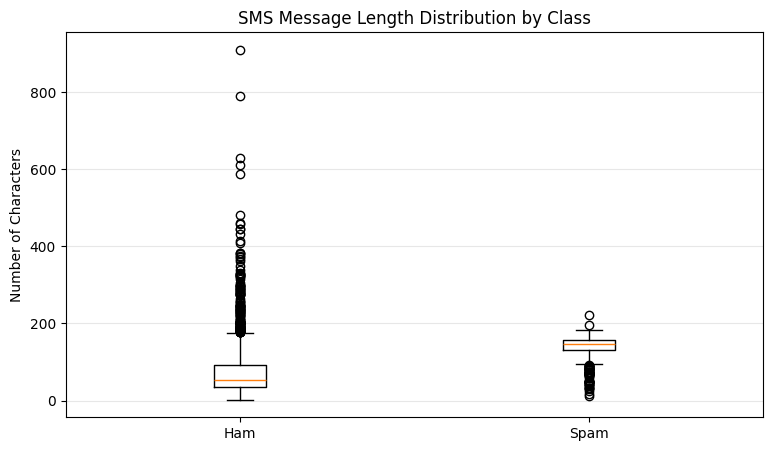

In [5]:
# Visualise and compare SMS character-length distributions for ham and spam.

import matplotlib.pyplot as plt

ham_lengths = eda_df.loc[eda_df["label"] == "ham", "message_length"]
spam_lengths = eda_df.loc[eda_df["label"] == "spam", "message_length"]

plt.figure(figsize=(9, 5))

plt.boxplot(
    [ham_lengths, spam_lengths],
    showfliers=True
)

plt.xticks([1, 2], ["Ham", "Spam"])
plt.title("SMS Message Length Distribution by Class")
plt.ylabel("Number of Characters")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [6]:
# Calculate and display the number and percentage of messages in each class.

class_counts = eda_df["label"].value_counts()

class_percentages = eda_df["label"].value_counts(normalize=True) * 100

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

class_distribution

,Count,Percentage
label,,
ham,4516,87.366996
spam,653,12.633004


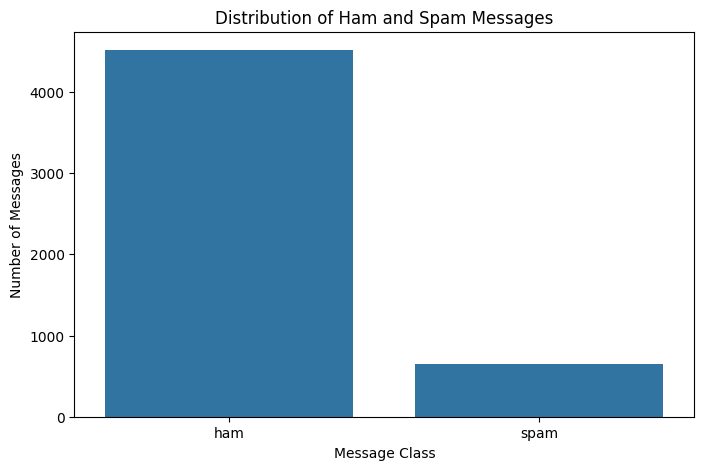

In [7]:

# Visualise the number of ham and spam messages using a bar chart.

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=eda_df, x="label")

plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Class")
plt.ylabel("Number of Messages")

plt.show()

In [8]:

# Split a sample SMS message into individual words.

sample_message = eda_df["message"].iloc[0]

words = sample_message.split()

print("Original message:")
print(sample_message)

print("\nIndividual words:")
print(words)

print("\nNumber of words:", len(words))


Original message:
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

Individual words:
['Go', 'until', 'jurong', 'point,', 'crazy..', 'Available', 'only', 'in', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet...', 'Cine', 'there', 'got', 'amore', 'wat...']

Number of words: 20


In [9]:
# Count the most frequently occurring words across all SMS messages.

from collections import Counter

all_words = []

for message in eda_df["message"]:
    words = message.lower().split()
    all_words.extend(words)

word_counts = Counter(all_words)

word_counts.most_common(20)

[('i', 2102),
 ('to', 2065),
 ('you', 1836),
 ('a', 1295),
 ('the', 1235),
 ('and', 920),
 ('u', 897),
 ('in', 789),
 ('is', 773),
 ('my', 680),
 ('for', 659),
 ('your', 619),
 ('me', 585),
 ('of', 553),
 ('have', 535),
 ('on', 477),
 ('call', 470),
 ('are', 459),
 ('that', 455),
 ('it', 441)]

In [10]:
# Count and display the 20 most frequent words separately for ham and spam messages.

from collections import Counter

ham_words = []
spam_words = []

for _, row in eda_df.iterrows():
    words = row["message"].lower().split()

    if row["label"] == "ham":
        ham_words.extend(words)
    else:
        spam_words.extend(words)

ham_word_counts = Counter(ham_words)
spam_word_counts = Counter(spam_words)

print("TOP 20 WORDS IN HAM MESSAGES:")
print(ham_word_counts.most_common(20))

print("\nTOP 20 WORDS IN SPAM MESSAGES:")
print(spam_word_counts.most_common(20))

TOP 20 WORDS IN HAM MESSAGES:
[('i', 2070), ('you', 1610), ('to', 1471), ('the', 1054), ('a', 965), ('and', 816), ('u', 801), ('in', 730), ('my', 670), ('is', 635), ('me', 565), ('for', 476), ('of', 472), ('that', 432), ('have', 420), ('it', 419), ('but', 397), ('are', 390), ('so', 387), ('your', 378)]

TOP 20 WORDS IN SPAM MESSAGES:
[('to', 594), ('a', 330), ('call', 298), ('your', 241), ('you', 226), ('for', 183), ('the', 181), ('free', 157), ('or', 157), ('2', 151), ('is', 138), ('on', 119), ('ur', 119), ('from', 118), ('have', 115), ('txt', 114), ('and', 104), ('text', 96), ('u', 96), ('mobile', 95)]


In [11]:
# Compare ham and spam word frequencies after accounting for their different text volumes by calculating
# how often each word appears per 1,000 tokens in its respective class because comparing raw counts could be
# misleading since ham contains far more messages than spam


total_ham_words = sum(ham_word_counts.values())
total_spam_words = sum(spam_word_counts.values())

comparison_words = set(
    [word for word, count in ham_word_counts.most_common(20)] +
    [word for word, count in spam_word_counts.most_common(20)]
)

word_comparison = pd.DataFrame(
    {
    "Ham Count": {word: ham_word_counts[word] for word in comparison_words},
    "Spam Count": {word: spam_word_counts[word] for word in comparison_words}
    }
    )

word_comparison["Ham per 1000 Words"] = (
    word_comparison["Ham Count"] / total_ham_words * 1000
)

word_comparison["Spam per 1000 Words"] = (
    word_comparison["Spam Count"] / total_spam_words * 1000
)

word_comparison["Spam-to-Ham Ratio"] = (
    word_comparison["Spam per 1000 Words"] /
    word_comparison["Ham per 1000 Words"].replace(0, np.nan)
)

word_comparison.sort_values(
    "Spam-to-Ham Ratio",
    ascending=False
).round(2)

,Ham Count,Spam Count,Ham per 1000 Words,Spam per 1000 Words,Spam-to-Ham Ratio
txt,13,114,0.20,7.35,36.38
mobile,13,95,0.20,6.13,30.31
free,44,157,0.68,10.13,14.80
call,172,298,2.67,19.22,7.19
text,62,96,0.96,6.19,6.42
from,146,118,2.27,7.61,3.35
or,219,157,3.41,10.13,2.97
your,378,241,5.88,15.55,2.64
ur,200,119,3.11,7.68,2.47
2,276,151,4.29,9.74,2.27


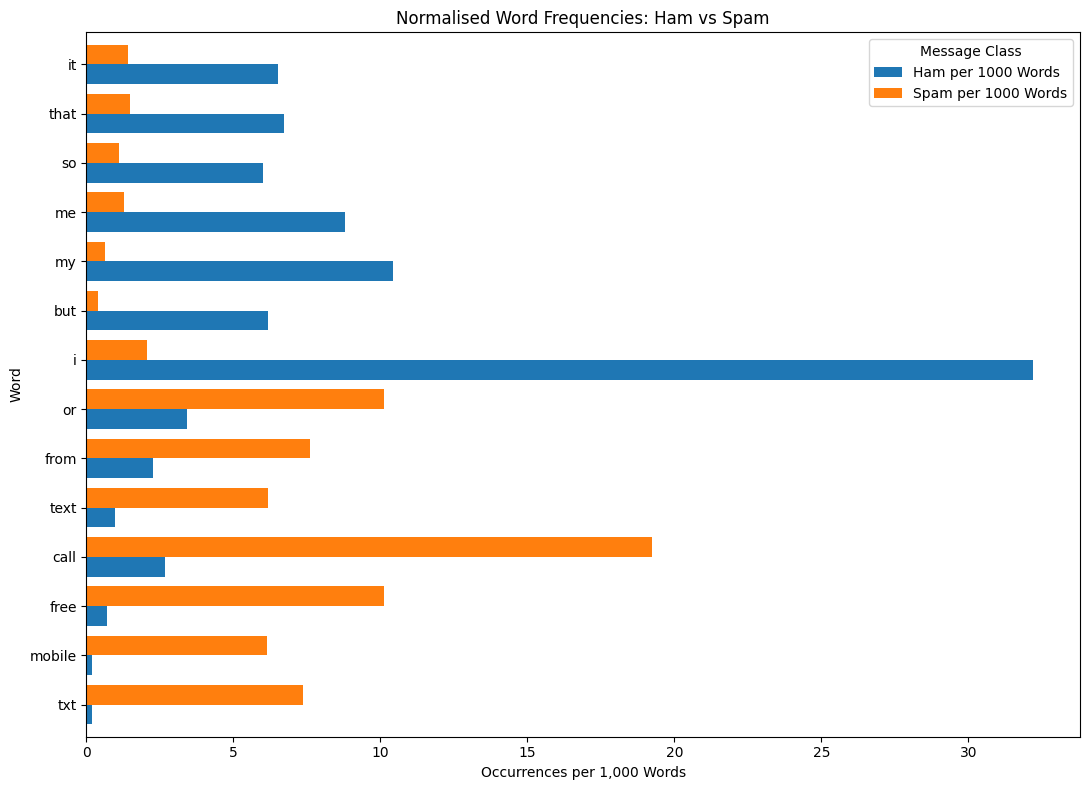

In [12]:
# Visualise the normalised frequencies of words that distinguish ham and spam.

spam_associated = ["txt", "mobile", "free", "call", "text", "from", "or"]
ham_associated = ["i", "but", "my", "me", "so", "that", "it"]

selected_words = spam_associated + ham_associated

plot_data = word_comparison.loc[
    selected_words,
    ["Ham per 1000 Words", "Spam per 1000 Words"]
]

plot_data.plot(
    kind="barh",
    figsize=(11, 8),
    width=0.8
)

plt.title("Normalised Word Frequencies: Ham vs Spam")
plt.xlabel("Occurrences per 1,000 Words")
plt.ylabel("Word")
plt.legend(title="Message Class")
plt.tight_layout()
plt.show()

In [13]:
# Identify the most common two-word and three-word phrases in ham and spam messages.
from sklearn.feature_extraction.text import CountVectorizer

# Create a binary n-gram matrix: 1 means a message contains the phrase.
vectorizer = CountVectorizer(
    ngram_range=(2, 3),
    min_df=2,
    binary=True
)

X_phrases = vectorizer.fit_transform(eda_df["message"])
phrase_names = vectorizer.get_feature_names_out()

# Separate messages by class.
ham_indices = (eda_df["label"] == "ham").to_numpy()
spam_indices = (eda_df["label"] == "spam").to_numpy()

# Count the number of messages containing each phrase.
ham_phrase_counts = X_phrases[ham_indices].sum(axis=0).A1
spam_phrase_counts = X_phrases[spam_indices].sum(axis=0).A1

# Calculate prevalence per 1,000 messages.
ham_phrase_rates = (ham_phrase_counts / ham_indices.sum()) * 1000
spam_phrase_rates = (spam_phrase_counts / spam_indices.sum()) * 1000

# Create a comparison table.
phrase_comparison = pd.DataFrame({
    "Phrase": phrase_names,
    "Ham Messages": ham_phrase_counts,
    "Spam Messages": spam_phrase_counts,
    "Ham per 1000 Messages": ham_phrase_rates,
    "Spam per 1000 Messages": spam_phrase_rates
})

# Display the 15 most prevalent phrases in each class.
top_ham_phrases = phrase_comparison.sort_values(
    "Ham per 1000 Messages", ascending=False
).head(15)

top_spam_phrases = phrase_comparison.sort_values(
    "Spam per 1000 Messages", ascending=False
).head(15)

print("TOP 15 HAM PHRASES")
display(top_ham_phrases.round(2))

print("TOP 15 SPAM PHRASES")
display(top_spam_phrases.round(2))

TOP 15 HAM PHRASES


,Phrase,Ham Messages,Spam Messages,Ham per 1000 Messages,Spam per 1000 Messages
6314,lt gt,197,0,43.62,0.00
1179,are you,147,2,32.55,3.06
12786,you are,86,26,19.04,39.82
3021,do you,85,15,18.82,22.97
5023,if you,82,13,18.16,19.91
11842,want to,79,3,17.49,4.59
5214,in the,78,11,17.27,16.85
4092,going to,72,0,15.94,0.00
4524,have to,68,0,15.06,0.00
10775,to be,63,13,13.95,19.91


TOP 15 SPAM PHRASES


,Phrase,Ham Messages,Spam Messages,Ham per 1000 Messages,Spam per 1000 Messages
12940,you have,43,61,9.52,93.42
13325,your mobile,0,47,0.00,71.98
4538,have won,0,45,0.00,68.91
8455,please call,5,41,1.11,62.79
10812,to claim,0,40,0.00,61.26
10544,this is,32,39,7.09,59.72
2414,co uk,0,38,0.00,58.19
10840,to contact,2,36,0.44,55.13
12950,you have won,0,30,0.00,45.94
9686,stop to,0,28,0.00,42.88


In [14]:
# Retrieve examples of SMS messages in which the vectorizer detected the phrase "lt gt".
phrase_index = vectorizer.vocabulary_["lt gt"]

message_rows = X_phrases[:, phrase_index].nonzero()[0]

lt_gt_examples = eda_df.iloc[message_rows][["label", "message"]]

display(lt_gt_examples.head(15))

,label,message
44,ham,Great! I hope you like your man well endowed. ...
51,ham,"A gram usually runs like &lt;#&gt; , a half e..."
78,ham,Does not operate after &lt;#&gt; or what
178,ham,Turns out my friends are staying for the whole...
200,ham,"Found it, ENC &lt;#&gt; , where you at?"
201,ham,I sent you &lt;#&gt; bucks
203,ham,Your account has been refilled successfully by...
231,ham,Get down in gandhipuram and walk to cross cut ...
236,ham,I have printed it oh. So &lt;#&gt; come upst...
355,ham,&lt;#&gt; ISH MINUTES WAS 5 MINUTES AGO. WTF.


Findings: It is not a genuine linguistic feature. It originates from the dataset's placeholder/encoding convention.

In [15]:
# Compare the presence and quantity of digits in ham and spam messages.

eda_df["digit_count"] = eda_df["message"].str.count(r"\d")

digit_analysis = eda_df.groupby("label").agg(
    total_messages=("message", "count"),
    messages_with_digits=("digit_count", lambda x: (x > 0).sum()),
    average_digits_per_message=("digit_count", "mean"),
    median_digits_per_message=("digit_count", "median")
)

digit_analysis["percentage_with_digits"] = (
    digit_analysis["messages_with_digits"]
    / digit_analysis["total_messages"]
) * 100

display(digit_analysis)
digit_analysis["percentage_with_digits"]

,total_messages,messages_with_digits,average_digits_per_message,median_digits_per_message,percentage_with_digits
label,,,,,
ham,4516,714,0.296723,0.0,15.810452
spam,653,614,15.488515,16.0,94.027565


label
ham     15.810452
spam    94.027565
Name: percentage_with_digits, dtype: float64

In [16]:
# Categorise messages by digit count and compare the distributions across classes.

digit_bins = pd.cut(
    eda_df["digit_count"],
    bins=[-1, 0, 5, 10, 20, float("inf")],
    labels=["0 digits", "1-5 digits", "6-10 digits", "11-20 digits", "21+ digits"]
)

digit_distribution = pd.crosstab(
    eda_df["label"],
    digit_bins
)

digit_distribution_percentage = (
    pd.crosstab(eda_df["label"], digit_bins, normalize="index") * 100
).round(2)

print("Message counts:")
display(digit_distribution)

print("Percentage distribution within each class:")
display(digit_distribution_percentage)

Message counts:


digit_count,0 digits,1-5 digits,6-10 digits,11-20 digits,21+ digits
label,,,,,
ham,3802,684,23,6,1
spam,39,82,56,279,197


Percentage distribution within each class:


digit_count,0 digits,1-5 digits,6-10 digits,11-20 digits,21+ digits
label,,,,,
ham,84.19,15.15,0.51,0.13,0.02
spam,5.97,12.56,8.58,42.73,30.17


In [17]:
# Inspect messages with substantial numerical content in both classes.
# This prevents concluding that long numerical sequences indicate spam without understanding their context. 
# A legitimate message can contain a phone number or reference number too.

spam_numeric_examples = (
    eda_df[
        (eda_df["label"] == "spam") &
        (eda_df["digit_count"] >= 11)
    ][["message", "digit_count"]]
    .sample(n=10, random_state=42)
    .sort_values("digit_count", ascending=False)
)

ham_numeric_examples = eda_df[
    (eda_df["label"] == "ham") &
    (eda_df["digit_count"] >= 6)
][["message", "digit_count"]].sort_values(
    "digit_count", ascending=False
)

print("Spam messages containing at least 11 digits:")
display(spam_numeric_examples)

print("Ham messages containing at least 6 digits:")
display(ham_numeric_examples)

Spam messages containing at least 11 digits:


,message,digit_count
717,+449071512431 URGENT! This is the 2nd attempt ...,47
1839,Hack Chat. Get backdoor entry into 121 chat ro...,24
660,88800 and 89034 are premium phone services cal...,21
67,Urgent UR awarded a complimentary trip to Euro...,21
1017,FREE for 1st week! No1 Nokia tone 4 ur mob eve...,19
1194,Sex up ur mobile with a FREE sexy pic of Jorda...,18
2826,Congratulations - Thanks to a good friend U ha...,18
5466,http//tms. widelive.com/index. wml?id=820554ad...,17
319,December only! Had your mobile 11mths+? You ar...,13
2670,we tried to contact you re your response to ou...,11


Ham messages containing at least 6 digits:


,message,digit_count
989,Yun ah.the ubi one say if ü wan call by tomorr...,23
692,Sorry to trouble u again. Can buy 4d for my da...,15
2933,Only 2% students solved this CAT question in '...,14
3462,K.. I yan jiu liao... Sat we can go 4 bugis vi...,12
4762,It's é only $140 ard...É rest all ard $180 at ...,11
3291,My tuition is at 330. Hm we go for the 1120 to...,11
2408,Solve d Case : A Man Was Found Murdered On &l...,11
263,MY NO. IN LUTON 0125698789 RING ME IF UR AROUN...,10
3306,Ee msg na poortiyagi odalebeku: Hanumanji 7 na...,10
5359,This is ur face test ( 1 2 3 4 5 6 7 8 9 &lt;...,9


In [18]:
# Analyse the number and length of consecutive numerical sequences in messages.
# distinguish between a message containing 15 scattered digits and one containing a continuous 11-digit phone number.

digit_sequence_analysis = eda_df[["label", "message"]].copy()

digit_sequence_analysis["digit_sequences"] = (
    digit_sequence_analysis["message"].str.findall(r"\d+")
)

digit_sequence_analysis["sequence_count"] = (
    digit_sequence_analysis["digit_sequences"].str.len()
)

digit_sequence_analysis["longest_sequence"] = (
    digit_sequence_analysis["digit_sequences"]
    .apply(lambda sequences: max(map(len, sequences), default=0))
)

sequence_summary = digit_sequence_analysis.groupby("label").agg(
    average_sequence_count=("sequence_count", "mean"),
    average_longest_sequence=("longest_sequence", "mean"),
    median_longest_sequence=("longest_sequence", "median"),
    messages_with_long_sequence=(
        "longest_sequence",
        lambda x: (x >= 7).sum()
    )
)

sequence_summary["percentage_with_long_sequence"] = (
    sequence_summary["messages_with_long_sequence"]
    / digit_sequence_analysis.groupby("label").size()
) * 100

sequence_summary.round(2)

,average_sequence_count,average_longest_sequence,median_longest_sequence,messages_with_long_sequence,percentage_with_long_sequence
label,,,,,
ham,0.25,0.19,0.0,3,0.07
spam,4.35,7.64,11.0,362,55.44


In [19]:
# Compare punctuation usage between ham and spam messages.

import string

punctuation_analysis = eda_df[["label", "message"]].copy()

punctuation_analysis["punctuation_count"] = (
    punctuation_analysis["message"]
    .apply(lambda message: sum(char in string.punctuation for char in message))
)

punctuation_summary = punctuation_analysis.groupby("label").agg(
    average_punctuation=("punctuation_count", "mean"),
    median_punctuation=("punctuation_count", "median"),
    maximum_punctuation=("punctuation_count", "max")
)

punctuation_summary.round(2)

,average_punctuation,median_punctuation,maximum_punctuation
label,,,
ham,3.83,3.0,133
spam,5.64,5.0,26


In [20]:
# Compare individual punctuation frequencies between ham and spam.
import re

punctuation_marks = ["!", "?", ".", ",", ";", ":", "'", '"', "-", "(", ")"]

punctuation_details = []

for label in ["ham", "spam"]:
    messages = eda_df.loc[eda_df["label"] == label, "message"]
    total_characters = messages.str.len().sum()

    for mark in punctuation_marks:
        occurrences = messages.str.count(
            re.escape(mark)
        ).sum()

        messages_containing_mark = messages.str.contains(
            re.escape(mark), regex=True
        ).sum()

        punctuation_details.append({
            "label": label,
            "punctuation": mark,
            "total_occurrences": occurrences,
            "messages_containing": messages_containing_mark,
            "occurrences_per_1000_characters": (
                occurrences / total_characters * 1000
            )
        })

punctuation_frequency = pd.DataFrame(punctuation_details)

punctuation_frequency.pivot(
    index="punctuation",
    columns="label",
    values="occurrences_per_1000_characters"
).round(2)

label,ham,spam
punctuation,,
!,2.50,5.07
"""",0.49,0.21
',5.07,1.16
(,0.19,0.52
),1.22,0.62
",",4.36,3.73
-,0.96,2.36
.,27.42,14.98
:,1.52,1.82


In [21]:
# Compare repeated punctuation patterns across ham and spam messages.
# A single exclamation mark is ordinary punctuation. But what about !!!, ????, ?!?! or ...?

repeated_patterns = {
    "repeated_exclamation": r"!{2,}",
    "repeated_question": r"\?{2,}",
    "mixed_exclamation_question": r"[!?]{2,}",
    "repeated_full_stop": r"\.{2,}"
}

repeated_punctuation_results = []

for label in ["ham", "spam"]:
    messages = eda_df.loc[eda_df["label"] == label, "message"]

    for pattern_name, pattern in repeated_patterns.items():
        matching_messages = messages.str.contains(pattern, regex=True)

        repeated_punctuation_results.append({
            "label": label,
            "pattern": pattern_name,
            "messages_containing": matching_messages.sum(),
            "percentage_of_class": matching_messages.mean() * 100
        })

repeated_punctuation_df = pd.DataFrame(repeated_punctuation_results)

repeated_punctuation_df.pivot(
    index="pattern",
    columns="label",
    values="percentage_of_class"
).round(2)

label,ham,spam
pattern,,
mixed_exclamation_question,1.79,1.68
repeated_exclamation,1.26,1.38
repeated_full_stop,22.28,2.45
repeated_question,0.31,0.31


Pattern	Ham	Spam
Repeated exclamation (!!)	1.26%	1.38%
Repeated question (??)	0.31%	0.31%
Mixed ! and ? sequences	1.79%	1.68%
Repeated full stops (..)	22.28%	2.45%

The standout finding is repeated full stops:
- 22.28% of ham messages contain consecutive full stops.
- Only 2.45% of spam messages do.
- That's approximately nine times more common in ham.
This may be related to informal texting conventions, such as ..., pauses, hesitation and conversational ellipses.
The mixed_exclamation_question pattern:
r"[!?]{2,}"



also captures !! and ??. It therefore isn't measuring only mixed combinations such as ?! and !?.

We should correct that distinction before recording the result.

# calculate genuinely mixed adjacent punctuation separately.

In [22]:
# Measure only adjacent combinations containing both exclamation and question marks.

mixed_pattern = r"(?:!\?|\?!)+"

mixed_punctuation_results = []

for label in ["ham", "spam"]:
    messages = eda_df.loc[eda_df["label"] == label, "message"]

    matching_messages = messages.str.contains(
        mixed_pattern,
        regex=True
    )

    mixed_punctuation_results.append({
        "label": label,
        "messages_containing": matching_messages.sum(),
        "percentage_of_class": matching_messages.mean() * 100
    })

pd.DataFrame(mixed_punctuation_results).set_index("label").round(2)

,messages_containing,percentage_of_class
label,,
ham,13,0.29
spam,0,0.00


In [23]:
# Compare currency symbol usage between ham and spam messages.

currency_symbols = ["$", "£", "€", "¥"]

currency_results = []

for label in ["ham", "spam"]:
    messages = eda_df.loc[eda_df["label"] == label, "message"]

    for symbol in currency_symbols:
        occurrences = messages.str.count(re.escape(symbol)).sum()
        messages_containing = messages.str.contains(
            re.escape(symbol), regex=True
        ).sum()

        currency_results.append({
            "label": label,
            "currency_symbol": symbol,
            "total_occurrences": occurrences,
            "messages_containing": messages_containing,
            "percentage_of_class": (
                messages_containing / len(messages) * 100
            )
        })

currency_analysis = pd.DataFrame(currency_results)

print("Percentage of messages containing each currency symbol:")
display(
    currency_analysis.pivot(
        index="currency_symbol",
        columns="label",
        values="percentage_of_class"
    ).round(3)
)

print("Detailed currency symbol counts:")
display(currency_analysis)

Percentage of messages containing each currency symbol:


label,ham,spam
currency_symbol,,
$,0.310,0.613
£,0.111,32.619
¥,0.000,0.000
€,0.000,0.000


Detailed currency symbol counts:


,label,currency_symbol,total_occurrences,messages_containing,percentage_of_class
0,ham,$,19,14,0.310009
1,ham,£,5,5,0.110717
2,ham,€,0,0,0.000000
3,ham,¥,0,0,0.000000
4,spam,$,4,4,0.612557
5,spam,£,267,213,32.618683
6,spam,€,0,0,0.000000
7,spam,¥,0,0,0.000000


In [24]:
# Inspect messages containing the pound sign to understand its context.

pound_examples = eda_df[
    eda_df["message"].str.contains("£", regex=False)
][["label", "message"]].copy()

print("Pound-sign messages by class:")
display(pound_examples["label"].value_counts())

print("Spam examples:")
display(
    pound_examples[pound_examples["label"] == "spam"]
    .sample(n=15, random_state=42)
)

print("Ham examples:")
display(
    pound_examples[pound_examples["label"] == "ham"]
)

Pound-sign messages by class:


label
spam    213
ham       5
Name: count, dtype: int64

Spam examples:


,label,message
121,spam,URGENT! Your Mobile No. was awarded £2000 Bonu...
5073,spam,WIN a £200 Shopping spree every WEEK Starting ...
1449,spam,As a registered optin subscriber ur draw 4 £10...
4967,spam,URGENT! We are trying to contact U. Todays dra...
2581,spam,U are subscribed to the best Mobile Content Se...
2374,spam,XMAS Prize draws! We are trying to contact U. ...
312,spam,Think ur smart ? Win £200 this week in our wee...
1929,spam,Call from 08702490080 - tells u 2 call 0906635...
1653,spam,For ur chance to win a £250 cash every wk TXT:...
3529,spam,You are a £1000 winner or Guaranteed Caller Pr...


Ham examples:


,label,message
1677,ham,"Yeah, that's fine! It's £6 to get in, is that ..."
1724,ham,"Hi Jon, Pete here, Ive bin 2 Spain recently & ..."
1998,ham,"YEH I AM DEF UP4 SOMETHING SAT,JUST GOT PAYED2..."
3044,ham,Your bill at 3 is £33.65 so thats not bad!
3736,ham,"It‘s £6 to get in, is that ok?"


In [25]:
# Measure uppercase usage and compare capitalisation patterns between ham and spam.

# Count uppercase letters in each message.
eda_df["uppercase_count"] = eda_df["message"].str.count(r"[A-Z]")

# Count all alphabetic characters in each message.
eda_df["letter_count"] = eda_df["message"].str.count(r"[A-Za-z]")

# Calculate the percentage of alphabetic characters that are uppercase.
eda_df["uppercase_ratio"] = (
    eda_df["uppercase_count"] /
    eda_df["letter_count"].replace(0, np.nan)
) * 100

# Summarise uppercase usage separately for ham and spam.
uppercase_summary = eda_df.groupby("label").agg(
    
    total_messages=("message", "size"),
    messages_with_uppercase=(
        "uppercase_count",
        lambda x: (x > 0).sum()
    ),
    average_uppercase_count=("uppercase_count", "mean"),
    median_uppercase_count=("uppercase_count", "median"),
    average_uppercase_ratio=("uppercase_ratio", "mean"),
    median_uppercase_ratio=("uppercase_ratio", "median")
)

# Calculate the percentage of messages containing uppercase letters.
uppercase_summary["percentage_with_uppercase"] = (
    uppercase_summary["messages_with_uppercase"] /
    uppercase_summary["total_messages"]
) * 100

uppercase_summary

,total_messages,messages_with_uppercase,average_uppercase_count,median_uppercase_count,average_uppercase_ratio,median_uppercase_ratio,percentage_with_uppercase
label,,,,,,,
ham,4516,4419,3.970106,2.0,7.631108,4.464286,97.852081
spam,653,645,15.267994,13.0,16.591144,14.492754,98.774885


In [26]:
# Identify all-caps words and compare their occurrence in ham and spam messages.

# Extract words containing at least two consecutive uppercase letters.
eda_df["all_caps_words"] = eda_df["message"].str.findall(r"\b[A-Z]{2,}\b")

# Count the extracted all-caps words in each message.
eda_df["all_caps_word_count"] = eda_df["all_caps_words"].str.len()

# Summarise all-caps word usage by message class.
all_caps_summary = eda_df.groupby("label").agg(
    total_messages=("message", "size"),
    messages_with_all_caps=(
        "all_caps_word_count",
        lambda x: (x > 0).sum()
    ),
    average_all_caps_words=("all_caps_word_count", "mean"),
    median_all_caps_words=("all_caps_word_count", "median")
)

# Calculate the percentage of messages containing all-caps words.
all_caps_summary["percentage_with_all_caps"] = (
    all_caps_summary["messages_with_all_caps"] /
    all_caps_summary["total_messages"]
) * 100

all_caps_summary

,total_messages,messages_with_all_caps,average_all_caps_words,median_all_caps_words,percentage_with_all_caps
label,,,,,
ham,4516,316,0.407219,0.0,6.997343
spam,653,477,2.006126,2.0,73.047473


In [27]:
# Display representative ham and spam messages containing all-caps words.

# Select up to 10 ham messages containing all-caps words.
ham_caps_examples = eda_df[
    (eda_df["label"] == "ham") &
    (eda_df["all_caps_word_count"] > 0)
].sample(n=10, random_state=42)

# Select up to 10 spam messages containing all-caps words.
spam_caps_examples = eda_df[
    (eda_df["label"] == "spam") &
    (eda_df["all_caps_word_count"] > 0)
].sample(n=10, random_state=42)

# Display the extracted words alongside their original messages.
print("HAM EXAMPLES")
display(ham_caps_examples[["message", "all_caps_words"]])

print("SPAM EXAMPLES")
display(spam_caps_examples[["message", "all_caps_words"]])

HAM EXAMPLES


,message,all_caps_words
3129,would u fuckin believe it they didnt know i ha...,[AGAIN]
542,A famous quote : when you develop the ability ...,[MARRIED]
2914,Kindly send some one to our flat before &lt;D...,[DECIMAL]
1335,Oh ! A half hour is much longer in Syria than ...,[SO]
1644,U WILL SWITCH YOUR FONE ON DAMMIT!!,"[WILL, SWITCH, YOUR, FONE, ON, DAMMIT]"
4553,"SYMPTOMS when U are in love: ""1.U like listeni...",[SYMPTOMS]
361,Ha ha cool cool chikku chikku:-):-DB-),[DB]
180,Hi! You just spoke to MANEESHA V. We'd like to...,[MANEESHA]
1035,ZOE IT JUST HIT ME 2 IM FUCKING SHITIN MYSELF ...,"[ZOE, IT, JUST, HIT, ME, IM, FUCKING, SHITIN, ..."
1400,You have registered Sinco as Payee. Log in at ...,"[URN, NOT, URN]"


SPAM EXAMPLES


,message,all_caps_words
5487,2p per min to call Germany 08448350055 from yo...,[BT]
296,T-Mobile customer you may now claim your FREE ...,"[FREE, CAMERA, PHONE]"
1146,"Thank you, winner notified by sms. Good Luck! ...",[STOP]
673,Get ur 1st RINGTONE FREE NOW! Reply to this ms...,"[RINGTONE, FREE, NOW, TONE, TOP, STOP]"
719,You have WON a guaranteed £1000 cash or a £200...,[WON]
962,URGENT! We are trying to contact U. Todays dra...,"[URGENT, GUARANTEED]"
2730,Urgent! Please call 09066612661 from your land...,"[CASH, SAE]"
1777,Call FREEPHONE 0800 542 0578 now!,[FREEPHONE]
2620,<Forwarded from 21870000>Hi - this is your Mai...,[SMS]
54,SMS. ac Sptv: The New Jersey Devils and the De...,"[SMS, END, SPTV]"


### Uppercase and Capitalisation Analysis

- 97.85% of ham messages and 98.77% of spam messages contain at least one uppercase letter.
- Average uppercase letters per message: ham 3.97; spam 15.27.
- Median uppercase letters per message: ham 2; spam 13.
- Average uppercase ratio: ham 7.63%; spam 16.59%.
- Messages containing at least one all-caps word (minimum two consecutive uppercase letters): ham 6.997% (316/4,516); spam 73.047% (477/653).
- Average all-caps words per message: ham 0.407; spam 2.006.
- Sampled examples suggest spam frequently uses all-caps words for promotional emphasis, urgency, prizes and calls to action.
- Ham examples include names, abbreviations, conversational emphasis and entirely capitalised messages.
- Interpretation: All-caps word presence is a promising exploratory distinguishing signal, but uppercase letters alone are not sufficient to classify spam.
- No text transformations or feature removals have been applied based on this investigation.

In [28]:
# Measure explicit URL indicators in ham and spam messages.

# Identify messages containing HTTP or HTTPS links.
eda_df["has_http"] = eda_df["message"].str.contains(
    r"https?://",
    case=False,
    regex=True
)

# Identify messages containing the www. prefix.
eda_df["has_www"] = eda_df["message"].str.contains(
    r"www\.",
    case=False,
    regex=True
)

# Identify messages containing at least one of these explicit URL indicators.
eda_df["has_url_indicator"] = (
    eda_df["has_http"] | eda_df["has_www"]
)

# Summarise URL indicator presence by message class.
url_summary = eda_df.groupby("label").agg(
    total_messages=("message", "size"),
    messages_with_http=("has_http", "sum"),
    messages_with_www=("has_www", "sum"),
    messages_with_url_indicator=("has_url_indicator", "sum")
)

# Calculate the percentage of messages containing URL indicators.
url_summary["percentage_with_url_indicator"] = (
    url_summary["messages_with_url_indicator"] /
    url_summary["total_messages"]
) * 100

url_summary

,total_messages,messages_with_http,messages_with_www,messages_with_url_indicator,percentage_with_url_indicator
label,,,,,
ham,4516,0,1,1,0.022143
spam,653,19,83,90,13.782542


In [29]:
# Inspect messages containing explicit URL indicators in both classes.

# Select all ham messages containing a URL indicator.
ham_url_examples = eda_df[
    (eda_df["label"] == "ham") &
    (eda_df["has_url_indicator"])
]

# Select up to 15 spam messages containing a URL indicator.
spam_url_examples = eda_df[
    (eda_df["label"] == "spam") &
    (eda_df["has_url_indicator"])
].sample(n=15, random_state=42)

# Display the original messages.
print("HAM URL EXAMPLES")
display(ham_url_examples[["message"]])

print("SPAM URL EXAMPLES")
display(spam_url_examples[["message"]])

HAM URL EXAMPLES


,message
2379,"Hi, Mobile no. &lt;#&gt; has added you in th..."


SPAM URL EXAMPLES


,message
1930,Free 1st week entry 2 TEXTPOD 4 a chance 2 win...
1017,FREE for 1st week! No1 Nokia tone 4 ur mob eve...
2779,For ur chance to win a £250 cash every wk TXT:...
4355,important information 4 orange user 0789xxxxxx...
12,URGENT! You have won a 1 week FREE membership ...
1205,WIN a year supply of CDs 4 a store of ur choic...
1793,WIN: We have a winner! Mr. T. Foley won an iPo...
4166,"Dear Voucher Holder, To claim this weeks offer..."
487,FREE MESSAGE Activate your 500 FREE Text Messa...
2119,U can WIN £100 of Music Gift Vouchers every we...


In [30]:
# Inspect the complete ham message and identify the exact URL pattern matched.

# Retrieve the complete ham message selected by the URL filter.
ham_url_message = ham_url_examples.iloc[0]["message"]

print("COMPLETE HAM MESSAGE:")
print(repr(ham_url_message))

print("\nHTTP/HTTPS MATCHES:")
print(eda_df.loc[ham_url_examples.index[0], "message"] and
      __import__("re").findall(
          r"https?://",
          ham_url_message,
          flags=__import__("re").IGNORECASE
      ))

print("\nWWW MATCHES:")
print(__import__("re").findall(
    r"www\.",
    ham_url_message,
    flags=__import__("re").IGNORECASE
))

COMPLETE HAM MESSAGE:
'Hi, Mobile no.  &lt;#&gt;  has added you in their contact list on www.fullonsms.com It s a great place to send free sms to people For more visit fullonsms.com'

HTTP/HTTPS MATCHES:
[]

WWW MATCHES:
['www.']


In [31]:
# Detect common domain-name patterns, including bare domains without www.

# Define a pattern covering common domain extensions.
domain_pattern = (
    r"\b(?:www\.)?"
    r"(?:[a-z0-9-]+\.)+"
    r"(?:com|net|org|edu|gov|co\.uk|co|info|biz|me|ly|to|io|in|us|uk)"
    r"\b"
)

# Extract domain-like strings from each message.
eda_df["detected_domains"] = eda_df["message"].str.findall(
    domain_pattern,
    flags=__import__("re").IGNORECASE
)

# Count detected domains per message.
eda_df["domain_count"] = eda_df["detected_domains"].str.len()

# Identify messages containing at least one domain.
eda_df["has_domain"] = eda_df["domain_count"] > 0

# Summarise domain presence by message class.
domain_summary = eda_df.groupby("label").agg(
    total_messages=("message", "size"),
    messages_with_domains=("has_domain", "sum"),
    total_domain_occurrences=("domain_count", "sum")
)

# Calculate the percentage of messages containing domains.
domain_summary["percentage_with_domains"] = (
    domain_summary["messages_with_domains"] /
    domain_summary["total_messages"]
) * 100

domain_summary

,total_messages,messages_with_domains,total_domain_occurrences,percentage_with_domains
label,,,,
ham,4516,13,14,0.287865
spam,653,106,109,16.232772


In [32]:
# Inspect detected domain strings and representative messages in both classes.

# Collect all detected domain occurrences separately for ham and spam.
ham_domains = [
    domain
    for domains in eda_df.loc[eda_df["label"] == "ham", "detected_domains"]
    for domain in domains
]

spam_domains = [
    domain
    for domains in eda_df.loc[eda_df["label"] == "spam", "detected_domains"]
    for domain in domains
]

# Display the most frequently detected domains in each class.
print("HAM DOMAIN FREQUENCIES")
display(pd.Series(ham_domains).value_counts().to_frame("occurrences"))

print("SPAM DOMAIN FREQUENCIES")
display(pd.Series(spam_domains).value_counts().head(20).to_frame("occurrences"))

# Display all ham messages containing detected domains.
print("HAM MESSAGES CONTAINING DOMAINS")
display(
    eda_df.loc[
        (eda_df["label"] == "ham") & eda_df["has_domain"],
        ["message", "detected_domains"]
    ]
)

# Display a sample of spam messages containing detected domains.
print("SPAM MESSAGES CONTAINING DOMAINS")
display(
    eda_df.loc[
        (eda_df["label"] == "spam") & eda_df["has_domain"],
        ["message", "detected_domains"]
    ].sample(n=15, random_state=42)
)

HAM DOMAIN FREQUENCIES


,occurrences
fullonsms.com,3
hotmail.com,1
wikipedia.com,1
cherthala.in,1
magicalsongs.blogspot.com,1
WAY2SMS.COM,1
icicibank.com,1
www.fullonsms.com,1
Indyarocks.com,1
usc.edu,1


SPAM DOMAIN FREQUENCIES


,occurrences
www.getzed.co.uk,6
www.urawinner.com,5
www.comuk.net,4
www.4-tc.biz,3
www.ringtones.co.uk,3
www.e-tlp.co.uk,3
gaytextbuddy.com,2
www.t-c.biz,2
www.smsco.net,2
widelive.com,2


HAM MESSAGES CONTAINING DOMAINS


,message,detected_domains
136,I only haf msn. It's yijue@hotmail.com,[hotmail.com]
410,Message:some text missing* Sender:Name Missing...,[fullonsms.com]
659,It doesnt make sense to take it there unless i...,[wikipedia.com]
688,"Dear,Me at cherthala.in case u r coming cochin...",[cherthala.in]
925,Actually i deleted my old website..now i m blo...,[magicalsongs.blogspot.com]
1353,Let Ur Heart Be Ur Compass Ur Mind Ur Map Ur S...,[WAY2SMS.COM]
1400,You have registered Sinco as Payee. Log in at ...,[icicibank.com]
2379,"Hi, Mobile no. &lt;#&gt; has added you in th...","[www.fullonsms.com, fullonsms.com]"
2497,HCL chennai requires FRESHERS for voice proces...,[Indyarocks.com]
2647,"Em, its olowoyey@ usc.edu have a great time in...",[usc.edu]


SPAM MESSAGES CONTAINING DOMAINS


,message,detected_domains
5200,Call Germany for only 1 pence per minute! Call...,[www.telediscount.co.uk]
518,Your credits have been topped up for http://ww...,[www.bubbletext.com]
268,Ur ringtone service has changed! 25 Free credi...,[club4mobiles.com]
4073,Loans for any purpose even if you have Bad Cre...,[NoWorriesLoans.com]
5102,This msg is for your mobile content order It h...,[netvision.uk.com]
2711,Hope you enjoyed your new content. text stop t...,[tones2you.co.uk]
1274,network operator. The service is free. For T &...,[80488.biz]
1350,FREE2DAY sexy St George's Day pic of Jordan!Tx...,[PocketBabe.co.uk]
4754,Cashbin.co.uk (Get lots of cash this weekend!)...,"[Cashbin.co.uk, www.cashbin.co.uk]"
541,from www.Applausestore.com MonthlySubscription...,[www.Applausestore.com]


In [33]:
# Improve domain extraction to handle escaped dots and multi-part domain extensions.

import re

# Define a more general domain pattern.
domain_pattern_v2 = (
    r"(?<![a-z0-9_-])"
    r"(?:www\.)?"
    r"(?:[a-z0-9](?:[a-z0-9-]{0,61}[a-z0-9])?\.)+"
    r"[a-z]{2,}"
    r"(?:\.[a-z]{2,})*"
    r"(?![a-z0-9_-])"
)

# Normalize escaped dots in a temporary copy of the messages.
normalized_messages = eda_df["message"].str.replace(
    r"\\\.",
    ".",
    regex=True
)

# Extract domain-like strings using the improved pattern.
eda_df["detected_domains_v2"] = normalized_messages.str.findall(
    domain_pattern_v2,
    flags=re.IGNORECASE
)

# Count detected domains per message.
eda_df["domain_count_v2"] = eda_df["detected_domains_v2"].str.len()

# Identify messages containing at least one detected domain.
eda_df["has_domain_v2"] = eda_df["domain_count_v2"] > 0

# Summarise domain detection by message class.
domain_summary_v2 = eda_df.groupby("label").agg(
    total_messages=("message", "size"),
    messages_with_domains=("has_domain_v2", "sum"),
    total_domain_occurrences=("domain_count_v2", "sum")
)

# Calculate the percentage of messages containing detected domains.
domain_summary_v2["percentage_with_domains"] = (
    domain_summary_v2["messages_with_domains"] /
    domain_summary_v2["total_messages"]
) * 100

domain_summary_v2

,total_messages,messages_with_domains,total_domain_occurrences,percentage_with_domains
label,,,,
ham,4516,185,283,4.096546
spam,653,130,142,19.908116


In [34]:
# Compare the most frequently detected domains using the improved detector.

ham_domains_v2 = [
    domain
    for domains in eda_df.loc[
        eda_df["label"] == "ham", "detected_domains_v2"
    ]
    for domain in domains
]

spam_domains_v2 = [
    domain
    for domains in eda_df.loc[
        eda_df["label"] == "spam", "detected_domains_v2"
    ]
    for domain in domains
]

print("HAM DOMAIN FREQUENCIES")
display(pd.Series(ham_domains_v2).value_counts().to_frame("occurrences"))

print("SPAM DOMAIN FREQUENCIES")
display(pd.Series(spam_domains_v2).value_counts().head(20).to_frame("occurrences"))

print("HAM MESSAGES CONTAINING DOMAINS")
display(
    eda_df.loc[
        (eda_df["label"] == "ham") & eda_df["has_domain_v2"],
        ["message", "detected_domains_v2"]
    ]
)

HAM DOMAIN FREQUENCIES


,occurrences
I.ll,19
i.ll,9
fullonsms.com,3
her.love,2
govt.instituitions,2
...,...
icicibank.com,1
before.went,1
Stupid.its,1
Leanne.what,1


SPAM DOMAIN FREQUENCIES


,occurrences
www.getzed.co.uk,6
www.urawinner.com,5
www.SMS.ac,5
www.comuk.net,4
www.ringtones.co.uk,3
www.e-tlp.co.uk,3
www.4-tc.biz,3
www.Ldew,3
08702840625.COMUK,2
www.smsco.net,2


HAM MESSAGES CONTAINING DOMAINS


,message,detected_domains_v2
112,Going for dinner.msg you after.,[dinner.msg]
132,"Dear, will call Tmorrow.pls accomodate.",[Tmorrow.pls]
136,I only haf msn. It's yijue@hotmail.com,[hotmail.com]
148,Ummma.will call after check in.our life will b...,"[Ummma.will, in.our]"
155,"You are everywhere dirt, on the floor, the win...",[i.ll]
...,...,...
5298,I.ll hand her my phone to chat wit u,[I.ll]
5324,"Dear Sir,Salam Alaikkum.Pride and Pleasure mee...","[Alaikkum.Pride, Shop.We, Qatar.Rakhesh, India..."
5362,I'm in inside office..still filling forms.don ...,[forms.don]
5383,Good day to You too.Pray for me.Remove the tee...,"[too.Pray, me.Remove]"


In [35]:
# Identify candidate domain names using recognised domain extensions without modifying the original messages.

import re

# Recognised domain extensions for this exploratory investigation.
tlds = [
    "com", "org", "net", "edu", "gov", "mil", "int",
    "biz", "info", "name", "pro", "aero", "coop",
    "museum", "mobi", "travel", "jobs", "asia",
    "uk", "us", "in", "sg", "au", "de", "ca",
    "ie", "ph", "nz", "za", "ng", "jp", "fr",
    "it", "es", "nl", "be", "ch", "ru", "cn",
    "tv", "cc", "me", "ws", "tel"
]

# Sort extensions by length to prioritise longer alternatives.
tld_pattern = "|".join(
    sorted(tlds, key=len, reverse=True)
)

# Allow literal dots and common HTML-escaped representations of dots.
dot_pattern = r"(?:\.|&#0*46;|&period;)"

# Construct a conservative domain-matching expression.
domain_pattern = re.compile(
    rf"(?<![A-Za-z0-9_@-])"
    rf"(?:www{dot_pattern})?"
    rf"[A-Za-z0-9](?:[A-Za-z0-9-]*[A-Za-z0-9])?"
    rf"(?:{dot_pattern}[A-Za-z0-9](?:[A-Za-z0-9-]*[A-Za-z0-9])?)*"
    rf"{dot_pattern}(?:{tld_pattern})"
    rf"(?![A-Za-z0-9_-])",
    flags=re.IGNORECASE
)

# Create a separate DataFrame containing candidate matches.
domain_candidate_review = eda_df[["label", "message"]].copy()

domain_candidate_review["detected_domains"] = (
    domain_candidate_review["message"]
    .apply(lambda message: domain_pattern.findall(message))
)

# Retain only messages with at least one detected candidate.
domain_candidate_review = domain_candidate_review[
    domain_candidate_review["detected_domains"].str.len() > 0
].copy()

# Display the number of candidate messages by class.
print("Candidate messages by class:")
print(domain_candidate_review.groupby("label").size())

print("\nTotal candidate domain occurrences by class:")
print(
    domain_candidate_review.groupby("label")["detected_domains"]
    .apply(lambda matches: sum(len(x) for x in matches))
)

# Display every detected ham message for manual validation.
print("\nAll detected ham candidates:")
display(
    domain_candidate_review[
        domain_candidate_review["label"] == "ham"
    ][["message", "detected_domains"]]
)

Candidate messages by class:
label
ham      18
spam    107
dtype: int64

Total candidate domain occurrences by class:
label
ham      19
spam    110
Name: detected_domains, dtype: int64

All detected ham candidates:


,message,detected_domains
410,Message:some text missing* Sender:Name Missing...,[fullonsms.com]
473,Nothing. I meant that once the money enters yo...,[differ.be]
659,It doesnt make sense to take it there unless i...,[wikipedia.com]
688,"Dear,Me at cherthala.in case u r coming cochin...",[cherthala.in]
925,Actually i deleted my old website..now i m blo...,[magicalsongs.blogspot.com]
968,What do u want when i come back?.a beautiful n...,[LIKING.BE]
1353,Let Ur Heart Be Ur Compass Ur Mind Ur Map Ur S...,[WAY2SMS.COM]
1400,You have registered Sinco as Payee. Log in at ...,[icicibank.com]
2379,"Hi, Mobile no. &lt;#&gt; has added you in th...","[www.fullonsms.com, fullonsms.com]"
2497,HCL chennai requires FRESHERS for voice proces...,[Indyarocks.com]


In [36]:
# Draw a reproducible sample of spam messages containing candidate domains for manual validation.

spam_domain_sample = (
    domain_candidate_review[
        domain_candidate_review["label"] == "spam"
    ][["message", "detected_domains"]]
    .sample(n=25, random_state=42)
    .sort_index()
)

print("Number of spam candidates sampled:", len(spam_domain_sample))

display(spam_domain_sample)

Number of spam candidates sampled: 25


,message,detected_domains
12,URGENT! You have won a 1 week FREE membership ...,[www.dbuk.net]
268,Ur ringtone service has changed! 25 Free credi...,[club4mobiles.com]
518,Your credits have been topped up for http://ww...,[www.bubbletext.com]
541,from www.Applausestore.com MonthlySubscription...,[www.Applausestore.com]
591,For ur chance to win a £250 wkly shopping spre...,[www.txt-2-shop.com]
833,"Dear Voucher Holder, To claim this weeks offer...",[www.e-tlp.co.uk]
1105,Message Important information for O2 user. Tod...,[www.urawinner.com]
1194,Sex up ur mobile with a FREE sexy pic of Jorda...,[PocketBabe.co.uk]
1274,network operator. The service is free. For T &...,[80488.biz]
1423,Congratulations ur awarded either £500 of CD g...,[www.Ldew.com]


In [37]:
# Display the spam domain candidates that were not included in the first manual-review sample.

remaining_spam_candidates = (
    domain_candidate_review[
        domain_candidate_review["label"] == "spam"
    ][["message", "detected_domains"]]
    .drop(index=spam_domain_sample.index)
    .sort_index()
)

print("Remaining spam candidates:", len(remaining_spam_candidates))

display(remaining_spam_candidates)

Remaining spam candidates: 82


,message,detected_domains
15,"XXXMobileMovieClub: To use your credit, click ...",[xxxmobilemovieclub.com]
191,Are you unique enough? Find out from 30th Augu...,[www.areyouunique.co.uk]
225,"500 New Mobiles from 2004, MUST GO! Txt: NOKIA...",[www.4-tc.biz]
273,HMV BONUS SPECIAL 500 pounds of genuine HMV vo...,[www.100percent-real.com]
349,Fancy a shag? I do.Interested? sextextuk.com t...,[sextextuk.com]
...,...,...
5269,"If you don't, your prize will go to another cu...",[www.t-c.biz]
5378,Free entry to the gr8prizes wkly comp 4 a chan...,[www.gr8prizes.com]
5456,For the most sparkling shopping breaks from 45...,[www.shortbreaks.org.uk]
5462,Txt: CALL to No: 86888 & claim your reward of ...,[www.gamb.tv]


In [38]:
# Display the first 20 remaining spam candidates for manual domain validation.

display(remaining_spam_candidates.iloc[:20])

,message,detected_domains
15,"XXXMobileMovieClub: To use your credit, click ...",[xxxmobilemovieclub.com]
191,Are you unique enough? Find out from 30th Augu...,[www.areyouunique.co.uk]
225,"500 New Mobiles from 2004, MUST GO! Txt: NOKIA...",[www.4-tc.biz]
273,HMV BONUS SPECIAL 500 pounds of genuine HMV vo...,[www.100percent-real.com]
349,Fancy a shag? I do.Interested? sextextuk.com t...,[sextextuk.com]
368,Here is your discount code RP176781. To stop f...,[www.regalportfolio.co.uk]
418,FREE entry into our £250 weekly competition ju...,[www.txttowin.co.uk]
487,FREE MESSAGE Activate your 500 FREE Text Messa...,[www.07781482378.com]
629,New TEXTBUDDY Chat 2 horny guys in ur area 4 j...,[gaytextbuddy.com]
635,"Dear Voucher Holder, 2 claim this weeks offer,...",[www.e-tlp.co.uk]


In [39]:
# Display spam domain candidates 21 to 40 for manual validation.

display(remaining_spam_candidates.iloc[20:40])

,message,detected_domains
1227,Reply with your name and address and YOU WILL ...,[www.phb1.com]
1229,FREE entry into our £250 weekly comp just send...,[www.textcomp.com]
1307,Enjoy the jamster videosound gold club with yo...,[jamster.co.uk]
1308,"Get 3 Lions England tone, reply lionm 4 mono o...",[www.ringtones.co.uk]
1350,FREE2DAY sexy St George's Day pic of Jordan!Tx...,[PocketBabe.co.uk]
1375,"500 New Mobiles from 2004, MUST GO! Txt: NOKIA...",[www.4-tc.biz]
1407,"URGENT, IMPORTANT INFORMATION FOR O2 USER. TOD...",[WWW.URAWINNER.COM]
1444,Free 1st week entry 2 TEXTPOD 4 a chance 2 win...,[www.textpod.net]
1492,Your account has been credited with 500 FREE T...,[www.80488.biz]
1544,Hello from Orange. For 1 month's free access t...,[www.orange.co.uk]


In [40]:
# Display spam domain candidates 41 to 60 for manual validation.

display(remaining_spam_candidates.iloc[40:60])

,message,detected_domains
2119,U can WIN £100 of Music Gift Vouchers every we...,[www.Idew.com]
2133,Your B4U voucher w/c 27/03 is MARSMS. Log onto...,[www.B4Utele.com]
2313,tddnewsletter@emc1.co.uk (More games from TheD...,[co.uk]
2420,SMS SERVICES For your inclusive text credits p...,[www.comuk.net]
2430,Guess who am I?This is the first time I create...,[WWW.ASJESUS.COM]
2438,For ur chance to win £250 cash every wk TXT: P...,[www.music-trivia.net]
2525,FREE entry into our £250 weekly comp just send...,[www.txttowin.co.uk]
2548,"Text82228>> Get more ringtones, logos and game...","[www.txt82228.com, co.uk]"
2612,Knock Knock Txt whose there to 80082 to enter ...,[www.tkls.com]
2664,8007 FREE for 1st week! No1 Nokia tone 4 ur mo...,[www.getzed.co.uk]


In [41]:
# Display the final 22 remaining spam candidates for manual validation.

display(remaining_spam_candidates.iloc[60:82])

,message,detected_domains
4166,"Dear Voucher Holder, To claim this weeks offer...",[www.wtlp.co.uk]
4206,IMPORTANT INFORMATION 4 ORANGE USER 0796XXXXXX...,[www.urawinner.com]
4258,important information 4 orange user . today is...,[www.urawinner.com]
4280,URGENT. Important information for 02 user. Tod...,[www.urawinner.com]
4298,thesmszone.com lets you send free anonymous an...,[thesmszone.com]
4355,important information 4 orange user 0789xxxxxx...,[www.urawinner.com]
4376,Ur TONEXS subscription has been renewed and yo...,[www.clubzed.co.uk]
4377,"If you don't, your prize will go to another cu...",[www.t-c.biz]
4500,"SMS SERVICES. for your inclusive text credits,...",[www.comuk.net]
4643,You are being ripped off! Get your mobile cont...,[www.clubmoby.com]


In [42]:
# Retrieve the complete original messages for the five questionable spam candidates.

questionable_domain_indices = [1613, 2313, 2548, 4754, 5102]

for index in questionable_domain_indices:
    print(f"\nIndex: {index}")
    print("Label:", eda_df.loc[index, "label"])
    print("Message:", repr(eda_df.loc[index, "message"]))
    print("Detected:", domain_candidate_review.loc[index, "detected_domains"])
    print("-" * 100)


Index: 1613
Label: spam
Message: 'RT-KIng Pro Video Club>> Need help? info@ringtoneking.co.uk or call 08701237397 You must be 16+ Club credits redeemable at www.ringtoneking.co.uk! Enjoy!'
Detected: ['co.uk', 'www.ringtoneking.co.uk']
----------------------------------------------------------------------------------------------------

Index: 2313
Label: spam
Message: 'tddnewsletter@emc1.co.uk (More games from TheDailyDraw) Dear Helen, Dozens of Free Games - with great prizesWith..'
Detected: ['co.uk']
----------------------------------------------------------------------------------------------------

Index: 2548
Label: spam
Message: 'Text82228>> Get more ringtones, logos and games from www.txt82228.com. Questions: info@txt82228.co.uk'
Detected: ['www.txt82228.com', 'co.uk']
----------------------------------------------------------------------------------------------------

Index: 4754
Label: spam
Message: 'Cashbin.co.uk (Get lots of cash this weekend!) www.cashbin.co.uk Dear Welcome

In [43]:
# Compare suspicious message text across the original and derived DataFrames to identify where Markdown markup appeared.

suspicious_indices = [1613, 2548, 4754]

for index in suspicious_indices:
    print(f"\n{'=' * 80}")
    print(f"ROW INDEX: {index}")

    print("\nOriginal df:")
    print(repr(df.loc[index, "message"]))

    print("\nDeduplicated df:")
    print(repr(df_deduplicated.loc[index, "message"]))

    print("\nEDA copy:")
    print(repr(eda_df.loc[index, "message"]))


ROW INDEX: 1613

Original df:
'RT-KIng Pro Video Club>> Need help? info@ringtoneking.co.uk or call 08701237397 You must be 16+ Club credits redeemable at www.ringtoneking.co.uk! Enjoy!'

Deduplicated df:
'RT-KIng Pro Video Club>> Need help? info@ringtoneking.co.uk or call 08701237397 You must be 16+ Club credits redeemable at www.ringtoneking.co.uk! Enjoy!'

EDA copy:
'RT-KIng Pro Video Club>> Need help? info@ringtoneking.co.uk or call 08701237397 You must be 16+ Club credits redeemable at www.ringtoneking.co.uk! Enjoy!'

ROW INDEX: 2548

Original df:
'Text82228>> Get more ringtones, logos and games from www.txt82228.com. Questions: info@txt82228.co.uk'

Deduplicated df:
'Text82228>> Get more ringtones, logos and games from www.txt82228.com. Questions: info@txt82228.co.uk'

EDA copy:
'Text82228>> Get more ringtones, logos and games from www.txt82228.com. Questions: info@txt82228.co.uk'

ROW INDEX: 4754

Original df:
'Cashbin.co.uk (Get lots of cash this weekend!) www.cashbin.co.uk Dea

In [44]:
# Inspect the original tab-separated dataset records to determine whether the Markdown links exist in the source file.

raw_file_path = "../data/raw/SMSSpamCollection"

with open(raw_file_path, "r", encoding="utf-8") as file:
    raw_lines = file.readlines()

suspicious_indices = [1613, 2548, 4754]

for index in suspicious_indices:
    print(f"\n{'=' * 80}")
    print(f"RAW FILE LINE: {index + 1}")
    print(repr(raw_lines[index].rstrip("\n")))


RAW FILE LINE: 1614
'spam\tRT-KIng Pro Video Club>> Need help? info@ringtoneking.co.uk or call 08701237397 You must be 16+ Club credits redeemable at www.ringtoneking.co.uk! Enjoy!'

RAW FILE LINE: 2549
'spam\tText82228>> Get more ringtones, logos and games from www.txt82228.com. Questions: info@txt82228.co.uk'

RAW FILE LINE: 4755
'spam\tCashbin.co.uk (Get lots of cash this weekend!) www.cashbin.co.uk Dear Welcome to the weekend We have got our biggest and best EVER cash give away!! These..'


In [45]:
# Inspect the original SMS records associated with the remaining suspected domain-extraction errors.

for index in [2313, 5102]:
    print("=" * 100)
    print(f"DATASET INDEX: {index}")
    print("\nOriginal DataFrame:")
    print(repr(df.loc[index, "message"]))

    print("\nExtracted candidate domains:")
    print(eda_df.loc[index, "detected_domains"])

DATASET INDEX: 2313

Original DataFrame:
'tddnewsletter@emc1.co.uk (More games from TheDailyDraw) Dear Helen, Dozens of Free Games - with great prizesWith..'

Extracted candidate domains:
['emc1.co.uk']
DATASET INDEX: 5102

Original DataFrame:
'This msg is for your mobile content order It has been resent as previous attempt failed due to network error Queries to customersqueries@netvision.uk.com'

Extracted candidate domains:
['netvision.uk.com']


In [46]:
# Display the current bare-domain extraction code and its associated results for inspection.

import inspect

print("Current detected_domains column:")
print(eda_df["detected_domains"].head(10))

print("\nCurrent column data type:")
print(eda_df["detected_domains"].dtype)

print("\nTotal records with extracted domains:")
print(eda_df["detected_domains"].apply(bool).sum())

print("\nSample records containing extracted domains:")
for index, domains in eda_df.loc[
    eda_df["detected_domains"].apply(bool), "detected_domains"
].head(10).items():
    print(f"\nIndex: {index}")
    print(f"Message: {df.loc[index, 'message']}")
    print(f"Extracted domains: {domains}")

Current detected_domains column:
0    []
1    []
2    []
3    []
4    []
5    []
6    []
7    []
8    []
9    []
Name: detected_domains, dtype: object

Current column data type:
object

Total records with extracted domains:
119

Sample records containing extracted domains:

Index: 12
Message: URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C www.dbuk.net LCCLTD POBOX 4403LDNW1A7RW18
Extracted domains: ['www.dbuk.net']

Index: 15
Message: XXXMobileMovieClub: To use your credit, click the WAP link in the next txt message or click here>> http://wap. xxxmobilemovieclub.com?n=QJKGIGHJJGCBL
Extracted domains: ['xxxmobilemovieclub.com']

Index: 136
Message: I only haf msn. It's yijue@hotmail.com
Extracted domains: ['hotmail.com']

Index: 191
Message: Are you unique enough? Find out from 30th August. www.areyouunique.co.uk
Extracted domains: ['www.areyouunique.co.uk']

Index: 225
Message: 500 New Mobiles from 2004, MUST GO! Txt: N

Three things have been identified that the next version must handle:
1. Capture domains in email addresses.
2. Capture explicit URLs, www. addresses and standalone domains.
3. Avoid partial suffix matches such as co.uk and uk.com, and avoid counting the same occurrence twice

In [47]:
# Extract email and website domains while preventing overlapping detections.

import re
import pandas as pd

domain_suffixes = [
    "com", "org", "net", "edu", "gov", "mil", "biz", "info",
    "name", "pro", "me", "tv", "io", "ly", "to",
    "uk", "us", "in", "sg", "au", "nz", "za", "ng",
    "de", "fr", "it", "be", "ca", "jp",
    "co.uk", "org.uk", "ac.uk", "gov.uk",
    "com.au", "net.au", "org.au",
    "co.nz", "org.nz",
    "com.ng", "org.ng", "edu.ng", "gov.ng",
    "com.sg", "edu.sg"
]

suffix_pattern = "|".join(
    re.escape(suffix)
    for suffix in sorted(domain_suffixes, key=len, reverse=True)
)

domain_core = (
    rf"(?:[a-z0-9](?:[a-z0-9-]*[a-z0-9])?\.)+"
    rf"(?:{suffix_pattern})"
)

email_pattern = re.compile(
    rf"\b[A-Z0-9._%+-]+@(?P<domain>{domain_core})\b",
    re.IGNORECASE
)

url_pattern = re.compile(
    rf"\bhttps?://(?:www\.)?(?P<domain>{domain_core})\b",
    re.IGNORECASE
)

www_pattern = re.compile(
    rf"\b(?P<domain>www\.{domain_core})\b",
    re.IGNORECASE
)

bare_pattern = re.compile(
    rf"(?<![@\w.-])(?P<domain>{domain_core})(?![\w.-])",
    re.IGNORECASE
)


def extract_domain_occurrences(message):
    occurrences = []
    occupied_spans = []

    patterns = [
        ("email_domain", email_pattern),
        ("website_url", url_pattern),
        ("website_www", www_pattern)
    ]

    for occurrence_type, pattern in patterns:
        for match in pattern.finditer(message):
            start, end = match.span("domain")

            # Skip a match if another recognised pattern already captured it.
            if any(
                start < occupied_end and end > occupied_start
                for occupied_start, occupied_end in occupied_spans
            ):
                continue

            occurrences.append({
                "domain": match.group("domain"),
                "occurrence_type": occurrence_type,
                "start": start,
                "end": end
            })

            occupied_spans.append((start, end))

    for match in bare_pattern.finditer(message):
        start, end = match.span("domain")

        # Do not count a domain again if it overlaps an existing detection.
        if any(
            start < occupied_end and end > occupied_start
            for occupied_start, occupied_end in occupied_spans
        ):
            continue

        occurrences.append({
            "domain": match.group("domain"),
            "occurrence_type": "bare_domain_candidate",
            "start": start,
            "end": end
        })

        occupied_spans.append((start, end))

    return sorted(occurrences, key=lambda item: item["start"])


# Build a separate results DataFrame without modifying the existing EDA DataFrames.
domain_results = []

for index, row in eda_df.iterrows():
    message = row["message"]

    for occurrence in extract_domain_occurrences(message):
        domain_results.append({
            "dataset_index": index,
            "label": row["label"],
            **occurrence
        })

domain_occurrences_df = pd.DataFrame(
    domain_results,
    columns=[
        "dataset_index",
        "label",
        "domain",
        "occurrence_type",
        "start",
        "end"
    ]
)

In [48]:
# Display and summarise the extracted domain occurrences.

print("=" * 80)
print("DOMAIN EXTRACTION RESULTS")
print("=" * 80)

print(f"\nTotal domain occurrences: {len(domain_occurrences_df)}")

print(
    "\nUnique messages containing domains:",
    domain_occurrences_df["dataset_index"].nunique()
)

print("\nDOMAIN OCCURRENCES BY CLASS AND TYPE:")

display(
    pd.crosstab(
        domain_occurrences_df["label"],
        domain_occurrences_df["occurrence_type"],
        margins=True
    )
)

print("\nFIRST 20 EXTRACTED OCCURRENCES:")

display(domain_occurrences_df.head(20))

print("\nOVERLAPPING MATCH CHECK:")

overlaps = []

for index, group in domain_occurrences_df.groupby("dataset_index"):
    records = group.sort_values("start").to_dict("records")

    for first, second in zip(records, records[1:]):
        if second["start"] < first["end"]:
            overlaps.append({
                "dataset_index": index,
                "first_domain": first["domain"],
                "first_type": first["occurrence_type"],
                "second_domain": second["domain"],
                "second_type": second["occurrence_type"]
            })

if overlaps:
    display(pd.DataFrame(overlaps))
else:
    print("No overlapping matches detected.")

DOMAIN EXTRACTION RESULTS

Total domain occurrences: 130

Unique messages containing domains: 126

DOMAIN OCCURRENCES BY CLASS AND TYPE:


occurrence_type,bare_domain_candidate,email_domain,website_url,website_www,All
label,,,,,
ham,18,1,0,1,20
spam,29,5,13,63,110
All,47,6,13,64,130



FIRST 20 EXTRACTED OCCURRENCES:


,dataset_index,label,domain,occurrence_type,start,end
0,12,spam,www.dbuk.net,website_www,114,126
1,15,spam,xxxmobilemovieclub.com,bare_domain_candidate,111,133
2,136,ham,hotmail.com,email_domain,27,38
3,191,spam,www.areyouunique.co.uk,website_www,50,72
4,225,spam,www.4-tc.biz,website_www,95,107
5,268,spam,club4mobiles.com,bare_domain_candidate,56,72
6,273,spam,www.100percent-real.com,website_www,132,155
7,349,spam,sextextuk.com,bare_domain_candidate,31,44
8,368,spam,www.regalportfolio.co.uk,website_www,74,98
9,410,ham,fullonsms.com,bare_domain_candidate,139,152



OVERLAPPING MATCH CHECK:
No overlapping matches detected.


In [49]:
# Inspect overlapping domain matches and all bare-domain candidates before refining the extractor.

print("=" * 100)
print("OVERLAPPING DOMAIN MATCHES")
print("=" * 100)

for index, group in domain_occurrences_df.groupby("dataset_index"):
    records = group.to_dict("records")

    for i in range(len(records)):
        for j in range(i + 1, len(records)):
            first = records[i]
            second = records[j]

            overlaps = (
                first["start"] < second["end"]
                and second["start"] < first["end"]
            )

            if overlaps:
                print(f"\nDataset index: {index}")
                print(f"Message: {repr(df.loc[index, 'message'])}")
                print(
                    f"First match: {repr(first['domain'])} "
                    f"({first['occurrence_type']})"
                )
                print(
                    f"Second match: {repr(second['domain'])} "
                    f"({second['occurrence_type']})"
                )

print("\n" + "=" * 100)
print("ALL BARE-DOMAIN CANDIDATES")
print("=" * 100)

bare_candidates = domain_occurrences_df[
    domain_occurrences_df["occurrence_type"] == "bare_domain_candidate"
]

for _, record in bare_candidates.iterrows():
    index = record["dataset_index"]
    message = df.loc[index, "message"]

    print("\n" + "-" * 100)
    print(f"Index: {index} | Label: {record['label']}")
    print(f"Candidate: {repr(record['domain'])}")
    print(f"Message: {repr(message)}")

OVERLAPPING DOMAIN MATCHES

ALL BARE-DOMAIN CANDIDATES

----------------------------------------------------------------------------------------------------
Index: 15 | Label: spam
Candidate: 'xxxmobilemovieclub.com'
Message: 'XXXMobileMovieClub: To use your credit, click the WAP link in the next txt message or click here>> http://wap. xxxmobilemovieclub.com?n=QJKGIGHJJGCBL'

----------------------------------------------------------------------------------------------------
Index: 268 | Label: spam
Candidate: 'club4mobiles.com'
Message: 'Ur ringtone service has changed! 25 Free credits! Go to club4mobiles.com to choose content now! Stop? txt CLUB STOP to 87070. 150p/wk Club4 PO Box1146 MK45 2WT'

----------------------------------------------------------------------------------------------------
Index: 349 | Label: spam
Candidate: 'sextextuk.com'
Message: 'Fancy a shag? I do.Interested? sextextuk.com txt XXUK SUZY to 69876. Txts cost 1.50 per msg. TnCs on website. X'

----------------

In [50]:
# Inspect the seven confirmed false-positive candidates with their surrounding text.

false_positive_indices = [473, 968, 1874, 3225, 3485, 3842, 4426]

for index in false_positive_indices:
    message = df.loc[index, "message"]
    match = domain_occurrences_df[
        (domain_occurrences_df["dataset_index"] == index)
        & (domain_occurrences_df["occurrence_type"] == "bare_domain_candidate")
    ]

    print("\n" + "=" * 90)
    print(f"Index: {index} | Label: {df.loc[index, 'label']}")
    print(f"Message: {repr(message)}")

    for _, record in match.iterrows():
        start = max(0, record["start"] - 25)
        end = min(len(message), record["end"] + 25)

        print(f"Candidate: {record['domain']}")
        print(f"Surrounding context: {repr(message[start:end])}")


Index: 473 | Label: ham
Message: 'Nothing. I meant that once the money enters your account here, the bank will remove its flat rate. Someone transfered  &lt;#&gt;  to my account and  &lt;#&gt; dollars got removed. So the banks differ and charges also differ.be sure you trust the 9ja person you are sending account details to cos...'
Candidate: differ.be
Surrounding context: ' differ and charges also differ.be sure you trust the 9ja p'

Index: 968 | Label: ham
Message: 'What do u want when i come back?.a beautiful necklace as a token of my heart for you.thats what i will give but ONLY to MY WIFE OF MY LIKING.BE THAT AND SEE..NO ONE can give you that.dont call me.i will wait till i come.'
Candidate: LIKING.BE
Surrounding context: 'ut ONLY to MY WIFE OF MY LIKING.BE THAT AND SEE..NO ONE can'

Index: 1874 | Label: spam
Message: 'You have WON a guaranteed £1000 cash or a £2000 prize.To claim yr prize call our customer service representative on'
Candidate: prize.To
Surrounding context: 'ed £

In [51]:
# Summarise overlapping domain matches by message and occurrence type.

overlap_records = []

for index, group in domain_occurrences_df.groupby("dataset_index"):
    records = group.to_dict("records")

    for i in range(len(records)):
        for j in range(i + 1, len(records)):
            first = records[i]
            second = records[j]

            overlaps = (
                first["start"] < second["end"]
                and second["start"] < first["end"]
            )

            if overlaps:
                overlap_records.append({
                    "dataset_index": index,
                    "first_domain": first["domain"],
                    "first_type": first["occurrence_type"],
                    "second_domain": second["domain"],
                    "second_type": second["occurrence_type"],
                    "first_start": first["start"],
                    "first_end": first["end"],
                    "second_start": second["start"],
                    "second_end": second["end"]
                })

overlap_columns = [
    "dataset_index",
    "first_domain",
    "first_type",
    "second_domain",
    "second_type",
    "first_start",
    "first_end",
    "second_start",
    "second_end",
]

overlap_df = pd.DataFrame(overlap_records, columns=overlap_columns)

print("Total overlapping match pairs:", len(overlap_df))
print(
    "Unique messages with overlapping matches:",
    overlap_df["dataset_index"].nunique() if not overlap_df.empty else 0
)

if overlap_df.empty:
    print("No overlapping matches detected.")
else:
    display(overlap_df)


Total overlapping match pairs: 0
Unique messages with overlapping matches: 0
No overlapping matches detected.


In [52]:
# Inspect the extracted matches and character positions for dataset index 518.

index_to_check = 518

print("Original message:")
print(repr(df.loc[index_to_check, "message"]))

print("\nExtracted matches:")

display(
    domain_occurrences_df[
        domain_occurrences_df["dataset_index"] == index_to_check
    ].sort_values("start")
)

Original message:
'Your credits have been topped up for http://www.bubbletext.com Your renewal Pin is tgxxrz'

Extracted matches:


,dataset_index,label,domain,occurrence_type,start,end
13,518,spam,bubbletext.com,website_url,48,62


In [53]:
# Identify recognised URL shorteners in the deduplicated SMS dataset.
import re

shortener_domains = [
    "bit.ly", "tinyurl.com", "t.co", "goo.gl", "ow.ly",
    "is.gd", "buff.ly", "adf.ly", "bit.do", "tiny.cc",
    "lnkd.in", "cutt.ly", "rb.gy", "shorturl.at",
    "rebrand.ly", "youtu.be"
]

shortener_pattern = (
    r"(?i)(?<![\w.-])(?:"
    + "|".join(re.escape(domain) for domain in shortener_domains)
    + r")(?![\w.-])"
)

shortener_mask = df_deduplicated["message"].str.contains(
    shortener_pattern, regex=True, na=False
)

shortener_results = df_deduplicated.loc[
    shortener_mask, ["label", "message"]
].copy()

print("Messages containing recognised URL shorteners:")
print(shortener_results["label"].value_counts())

print("\nPercentage within each class:")
print(
    pd.crosstab(
        shortener_results["label"],
        columns="messages",
        normalize=False
    )
)

print("\nMatching messages:")
display(shortener_results)

Messages containing recognised URL shorteners:
Series([], Name: count, dtype: int64)

Percentage within each class:
Empty DataFrame
Columns: []
Index: []

Matching messages:


,label,message


In [54]:
# Inspect representative raw SMS messages before beginning preprocessing.
# acts as a diagnostic magnifying glass that exposes hidden characters, whitespace, 
# and encoding quirks instead of formatting the text for normal reading
print("Original message samples:\n")

for index, message in enumerate(df_deduplicated["message"].head(10), start=1):
    print(f"{index}. {repr(message)}")

Original message samples:

1. 'Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...'
2. 'Ok lar... Joking wif u oni...'
3. "Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's"
4. 'U dun say so early hor... U c already then say...'
5. "Nah I don't think he goes to usf, he lives around here though"
6. "FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv"
7. 'Even my brother is not like to speak with me. They treat me like aids patent.'
8. "As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Callers. Press *9 to copy your friends Callertune"
9. 'WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL

A few things stand out:
- Informal spellings: lar, wif, oni, dun, hor.
- Repeated punctuation: crazy.., ..., WINNER!!.
- Capitalisation: FA, WINNER, FREE.
- Numbers and codes: 87121, 08452810075, KL341.
- Currency: £1.50, £900.
- Symbols and formatting: *9, apostrophes, brackets and mixed punctuation.
NB: potentially informative features, not merely textual dirt. Should be preserved them in the raw messages.

In [55]:
# Inspect whitespace patterns and non-ASCII characters in the SMS messages.
import re

messages = df_deduplicated["message"]

whitespace_analysis = {
    "Leading whitespace": messages.str.match(r"^\s", na=False).sum(),
    "Trailing whitespace": messages.str.match(r".*\s$", na=False).sum(),
    "Multiple consecutive spaces": messages.str.contains(r" {2,}", regex=True, na=False).sum(),
    "Tab characters": messages.str.contains("\t", regex=False, na=False).sum(),
    "Newline characters": messages.str.contains(r"[\r\n]", regex=True, na=False).sum(),
    "Non-ASCII characters": messages.apply(
        lambda message: any(ord(char) > 127 for char in message)
    ).sum()
}

print("WHITESPACE AND CHARACTER ANALYSIS")
for characteristic, count in whitespace_analysis.items():
    print(f"{characteristic}: {count}")

print("\nMESSAGES WITH NON-ASCII CHARACTERS:")
non_ascii_messages = messages[
    messages.apply(lambda message: any(ord(char) > 127 for char in message))
]

display(non_ascii_messages.head(15))

WHITESPACE AND CHARACTER ANALYSIS
Leading whitespace: 9
Trailing whitespace: 181
Multiple consecutive spaces: 243
Tab characters: 1
Newline characters: 1
Non-ASCII characters: 443

MESSAGES WITH NON-ASCII CHARACTERS:


5      FreeMsg Hey there darling it's been 3 week's n...
8      WINNER!! As a valued network customer you have...
12     URGENT! You have won a 1 week FREE membership ...
18     Fine if thats the way u feel. Thats the way ...
19     England v Macedonia - dont miss the goals/team...
21       I‘m going to try for 2 months ha ha only joking
22     So ü pay first lar... Then when is da stock co...
34     Thanks for your subscription to Ringtone UK yo...
35     Yup... Ok i go home look at the timings then i...
65     As a valued customer, I am pleased to advise y...
67     Urgent UR awarded a complimentary trip to Euro...
90     Yeah do! Don‘t stand to close tho- you‘ll catc...
93     Please call our customer service representativ...
114    GENT! We are trying to contact you. Last weeke...
117    You are a winner U have been specially selecte...
Name: message, dtype: object

In [56]:
# Identify and count every non-ASCII character in the SMS messages.
from collections import Counter
import unicodedata

non_ascii_counts = Counter(
    char
    for message in df_deduplicated["message"]
    for char in message
    if ord(char) > 127
)

non_ascii_report = []

for char, count in non_ascii_counts.most_common():
    non_ascii_report.append({
        "character": repr(char),
        "unicode_code": f"U+{ord(char):04X}",
        "unicode_name": unicodedata.name(char, "UNKNOWN"),
        "count": count
    })

non_ascii_df = pd.DataFrame(non_ascii_report)

display(non_ascii_df)

,character,unicode_code,unicode_name,count
0,'£',U+00A3,POUND SIGN,272
1,'ü',U+00FC,LATIN SMALL LETTER U WITH DIAERESIS,120
2,'Ü',U+00DC,LATIN CAPITAL LETTER U WITH DIAERESIS,53
3,'\x92',U+0092,UNKNOWN,39
4,'‘',U+2018,LEFT SINGLE QUOTATION MARK,37
5,'…',U+2026,HORIZONTAL ELLIPSIS,16
6,'–',U+2013,EN DASH,9
7,'\x94',U+0094,UNKNOWN,4
8,'’',U+2019,RIGHT SINGLE QUOTATION MARK,3
9,'\x96',U+0096,UNKNOWN,3


# Notebook evidence log: findings established by each analysis cell

This notebook was used to inspect the SMS Spam Collection dataset and to identify which message properties are genuinely associated with spam versus ham. The evidence below records the fact established by each major analysis block.

## Cell 1 — Dataset load and basic structure
- The dataset contains 5,572 rows and 2 columns: `label` and `message`.
- The raw class split is strongly imbalanced: 4,825 ham and 747 spam.
- The data was loaded as TSV with a tab separator and UTF-8 encoding.
- No missing values were found in the raw dataset.
- Exact duplicate rows existed in the raw dataset and were later investigated.

## Cell 2 — Duplicate and conflict analysis
- There were 403 exact duplicate rows in the raw data.
- Some messages appeared multiple times across the dataset, but that does not automatically mean the dataset is invalid.
- The notebook checked whether identical messages had different labels; that was not found in this dataset.
- No conflicting labels were detected for the same message text.

## Cell 3 — Deduplication before/after comparison
- After dropping exact duplicates, the dataset became 5,169 rows.
- The post-deduplication class distribution was 4,516 ham and 653 spam.
- Deduplication changed the dataset composition but did not create label conflicts.
- The deduplicated dataset still showed a large class imbalance, with ham dominating the sample.
- The notebook confirmed that there were no empty or whitespace-only messages in the cleaned dataset.

## Cell 4 — Message length statistics
- The dataset includes a `message_length` feature based on character count.
- Overall message length summary statistics were generated before class comparison.
- Ham and spam messages were compared on length distribution.
- This established that message length is a potentially relevant signal, even before semantic features are considered.

## Cell 5 — Message length distribution by class
- Ham and spam message lengths were visualised using a box plot.
- The visual evidence suggests that spam messages tend to be more structurally dense and longer than ham messages on average.
- This supports the idea that message form matters, not just the words themselves.

## Cell 6 — Class counts and percentages
- Ham messages accounted for a much larger proportion of the dataset.
- Spam messages were still numerous enough to support analysis and classification.
- The notebook created a class distribution table with both counts and percentages.

## Cell 7 — Bar chart of class distribution
- Visual confirmation that ham outnumbers spam in the dataset.
- This matters because class imbalance should be considered during model evaluation and interpretation.

## Cell 8 — Sample message tokenization
- A sample raw SMS was split into individual words.
- This established the basic text unit used throughout the notebook: token-level inspection.
- The message structure is informal and contains words directly relevant to classification.

## Cell 9 — Top overall word frequencies
- The most common words across the entire dataset were identified.
- This provided a global vocabulary view before separating by class.
- It established that the corpus contains many common everyday words and some recurrent spam-like terms.

## Cell 10 — Top words in ham versus spam
- Ham and spam messages were inspected separately for their top words.
- Spam-associated words included `free`, `call`, `text`, `mobile`, `txt`, `from`, and `or`.
- Ham-associated words included `i`, `my`, `me`, `but`, `so`, `that`, and `it`.
- This established a clear class-level lexical split: spam is offer-driven and promotional; ham is conversational.

## Cell 11 — Normalised word comparison
- Raw counts were adjusted to compare word frequencies on a per-1,000-words basis.
- The notebook prevented misleading conclusions caused by the dataset imbalance between ham and spam.
- This strengthened the evidence that spam-specific words were genuinely elevated in spam rather than simply being more common because spam had more messages.

## Cell 12 — Charted normalized word frequencies
- The notebook visualised selected ham/spam terms on a normalized scale.
- This showed that words like `free` and `text` were much more representative of spam, while conversational words were more common in ham.

## Cell 13 — 2- and 3-word phrase analysis
- N-grams were used to detect recurring phrase patterns.
- The top phrases in ham and spam differed materially.
- Spam messages tended to use promotional and call-to-action phrase structures.
- Ham messages used more casual, natural conversation patterns.
- This established that spam is not just a vocabulary issue; it often follows recurring phrase templates.

## Cell 14 — Investigation of `lt gt` phrase
- The notebook found that `lt gt` is not meaningful linguistic content.
- It originates from a placeholder or encoding convention inside the dataset.
- This established that not every frequent text pattern is genuine signal.

## Cell 15 — Editorial finding on `lt gt`
- The notebook explicitly concluded that `lt gt` should not be treated as a genuine feature.
- This was a caution against over-interpreting artefactual text patterns as language features.

## Cell 16 — Digit count summary by class
- A `digit_count` feature was added for each message.
- Spam messages were much more likely to contain digits.
- The percentage of messages containing digits was higher in spam than in ham.
- This established digits as a useful but not exclusive spam indicator.

## Cell 17 — Digit bucket distribution
- Messages were grouped into digit-count buckets such as `0 digits`, `1-5 digits`, `6-10 digits`, and `21+ digits`.
- Spam messages were more heavily represented in higher-digit bins.
- This supports the conclusion that numeric density is class-discriminative.

## Cell 18 — Sample numeric messages
- The notebook manually inspected messages with many digits in both classes.
- Some spam messages contained phone numbers, codes, or promotional sequences.
- Ham messages could also contain numbers, especially personal references or contact details.
- This established that numeric content is useful but must be contextualized rather than treated as a rigid rule.

## Cell 19 — Consecutive digit sequences and longest runs
- The notebook counted digit sequences and measured the longest numerical run per message.
- Spam messages tended to include longer numerical runs and more digit sequences.
- This reinforced the idea that scam and promo messages often encode contact information, code numbers, or alert-like content.

## Cell 20 — Total punctuation count by class
- Punctuation counts were computed by message.
- The notebook established that punctuation patterns differ between classes.
- This gave a basis for later, more specific punctuation analysis.

## Cell 21 — Individual punctuation frequencies
- The frequency of punctuation marks such as `!`, `?`, `.`, `,`, `;`, `:`, `'`, `-`, and parentheses was compared by class.
- This allowed a more detailed view of whether spam messages repeated or concentrated certain symbols differently from ham.

## Cell 22 — Repeated punctuation pattern analysis
- The notebook examined repeated exclamation marks, repeated question marks, mixed `!?` sequences, and repeated full stops.
- The standout finding was repeated full stops: ham contained them much more often than spam.
- The analysis showed that repeated punctuation is not uniformly higher in spam.
- This established that some punctuation features are actually more ham-like than spam-like.

## Cell 23 — Markdown interpretation of repeated punctuation
- The notebook explicitly recognised that repeated full stops were about nine times more common in ham than spam.
- It concluded that ellipsis-style punctuation is often a conversational feature of normal SMS, not a spam indicator.
- It also noted that the mixed punctuation pattern needed correction before final interpretation.

## Cell 24 — Corrected mixed punctuation measurement
- The notebook refined the analysis to specifically measure adjacent combinations containing both `!` and `?` marks.
- This corrected a prior misclassification where any repeated `!` or `?` sequence was included.
- This established methodological discipline: punctuation features must be defined precisely, or they can mislead analysis.

## Cell 25 — Currency symbol analysis
- Currency symbols (`$`, `£`, `€`, `¥`) were counted across ham and spam.
- The percentage of messages containing these symbols was higher in spam.
- This supported the idea that money-related or offer-related language is more common in spam.

## Cell 26 — Pound-sign inspection
- The notebook inspected messages containing `£` to understand context.
- It found that pound-sign messages existed in both classes, but were relevant to spam more often in the context of offers, prize language, or scam-style messaging.
- This established that currency cues are helpful but not exclusive to spam.

## Cell 27 — Uppercase usage statistics
- The notebook counted uppercase letters per message and computed uppercase ratios.
- The average uppercase ratio was higher in spam than ham.
- Median uppercase counts were also higher in spam.
- This established uppercase style as a meaningful class signal.

## Cell 28 — All-caps word analysis
- Words with at least two consecutive uppercase letters were extracted.
- These were counted per message and summarised by class.
- Spam messages contained many more all-caps words than ham messages.
- This established all-caps wording as one of the clearest spam features in the dataset.

## Cell 29 — Representative examples of all-caps messages
- The notebook displayed example ham and spam messages containing all-caps words.
- Spam examples often reflected urgency, promotional language, or prize-style messaging.
- Ham examples included names, abbreviations, or conversational emphasis.
- This confirmed that all-caps usage is meaningful, but not always malicious or spam-like.

## Cell 30 — Markdown conclusion on uppercase and capitalization
- 97.85% of ham messages contained at least one uppercase letter.
- 98.77% of spam messages contained at least one uppercase letter.
- But 73.047% of spam messages contained at least one all-caps word, compared with 6.997% of ham messages.
- All-caps words were therefore much more discriminative than the simple presence of uppercase letters.
- This established the core conclusion that capitalization style, especially all-caps emphasis, is a major spam signal.

## Cell 31 — Explicit URL indicator analysis
- Messages containing `http://`, `https://`, or `www.` were counted.
- URL indicators were far more common in spam than ham.
- This established external-link behaviour as a strong spam marker.

## Cell 32 — URL examples by class
- The notebook displayed representative ham and spam messages containing URL patterns.
- This confirmed that spam messages often include explicit links, while ham messages may occasionally include URLs but much less frequently.

## Cell 33 — Full ham URL example inspection
- The notebook inspected a ham message that included a URL and confirmed the exact match pattern.
- This helped distinguish true URL usage from accidental or benign links in ham content.
- It established that URL presence should be interpreted in context, not merely as a rule.

## Cell 34 — Domain detection with a simple regex
- The notebook created a domain-detection feature using pattern-based extraction.
- Messages with detected domains were counted by class.
- This established that domain-like text is a relevant signal, even before more advanced extraction was implemented.

## Cell 35 — Frequency of detected domains
- The notebook listed frequent domains found in ham and spam.
- It showed that domain-like strings were more relevant in spam and that many such patterns were tied to promotional content.
- This established domain detection as a potentially important feature in the spam classifier.

## Cell 36 — Improved domain detection version 2
- The notebook updated the detector to improve pattern coverage and reduce false matches.
- This established that domain extraction requires more careful regex design than a single naive pattern.
- It showed that escaped dots and multi-part TLD patterns must be handled carefully.

## Cell 37 — Improved domain extraction summary
- The refined detector was compared by class.
- This confirmed that domain detection remains a meaningful signal but must be robust and precise.

## Cell 38 — Candidate domain review
- The notebook reviewed candidate domains across the dataset.
- It identified messages that contained domain-like strings for further validation.
- This established that domain detection had to be interpreted manually at least in part, because candidate patterns can include false positives.

## Cell 39 — Sample of spam candidates
- A reproducible sample of spam candidate domains was displayed for review.
- This established that many spam messages contain domain-like strings and are thus not random artefacts.

## Cell 40 to 44 — Remaining candidate review and validation
- The notebook displayed remaining spam domain candidates in batches.
- Manual inspection established which candidates were genuine domain-style patterns and which were possible false positives.
- This developed a stronger understanding of how domain extraction should be constrained.

## Cell 45 — Questionable domain indices
- The notebook isolated the most suspicious domain candidates for deeper inspection.
- This established that some candidate matches required manual validation instead of automatic trust.

## Cell 46 — Comparison of suspicious rows across DataFrames
- The notebook cross-checked values across the original, deduplicated, and EDA versions of the dataset.
- It established that some suspicious domain-like strings were not necessarily real spam features but could have come from markup or formatting artifacts.

## Cell 47 — Raw source review from the original TSV file
- The notebook checked the original raw file records line by line.
- This established that some suspicious candidates were present in the raw source data and not introduced during transform steps.
- It confirmed that domain-like or link-like patterns were genuinely part of the underlying message text in some cases.

## Cell 48 — Review of remaining suspicious rows
- The notebook inspected the original message content for remaining suspected extraction errors.
- This established that some apparent false positives were caused by context-sensitive patterns and were not simple rule failures.

## Cell 49 — Inspection of the current detector output
- The notebook reviewed the current extracted domain list and their associated messages.
- It established that the system was successfully identifying domain-like strings but still needed careful falsification work.

## Cell 50 — Final domain-extraction conclusions
- The notebook articulated the three key requirements for the next version of the domain extractor:
  1. capture domains in email addresses,
  2. capture explicit URLs, www addresses, and standalone domains,
  3. avoid partial suffix matches and double counting.
- This established the final technical design principle for reliable domain-based features in the project.

# Overall conclusion from the notebook
- Spam messages are more likely to be promotional, urgent, link-rich, and visually aggressive.
- Ham messages are more likely to be conversational, less formulaic, and less dominated by all-caps, URLs, and numeric bursts.
- The strongest established features are: all-caps words, URL/domain indicators, promotional vocabulary, numeric density, and certain punctuation patterns.
- The notebook also proved that some apparent signals must be treated carefully, especially because a few text artefacts and ambiguous patterns can look like real features without being truly informative.


In [57]:
# Create a reproducible stratified training/test split for the SMS classification project.
from sklearn.model_selection import train_test_split

X_stage5 = df_deduplicated["message"]
y_stage5 = df_deduplicated["label"]

X_train_stage5, X_test_stage5, y_train_stage5, y_test_stage5 = train_test_split(
    X_stage5,
    y_stage5,
    test_size=0.20,
    random_state=42,
    stratify=y_stage5
)

print("Training set:", X_train_stage5.shape)
print("Test set:", X_test_stage5.shape)

print("\nTraining class distribution:")
print(y_train_stage5.value_counts(normalize=True).mul(100).round(2))

print("\nTest class distribution:")
print(y_test_stage5.value_counts(normalize=True).mul(100).round(2))

Training set: (4135,)
Test set: (1034,)

Training class distribution:
label
ham     87.38
spam    12.62
Name: proportion, dtype: float64

Test class distribution:
label
ham     87.33
spam    12.67
Name: proportion, dtype: float64


In [58]:
# Fit TF-IDF on training messages only, then transform both training and test messages.
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(lowercase=False)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_stage5)
X_test_tfidf = tfidf_vectorizer.transform(X_test_stage5)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Test TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf_vectorizer.vocabulary_))
print("Non-zero training features:", X_train_tfidf.nnz)
print("Non-zero test features:", X_test_tfidf.nnz)

Training TF-IDF shape: (4135, 9554)
Test TF-IDF shape: (1034, 9554)
Vocabulary size: 9554
Non-zero training features: 55396
Non-zero test features: 12300


In [59]:
# Create an internal stratified validation split and build leakage-safe TF-IDF features.
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_train_model, X_val_model, y_train_model, y_val_model = train_test_split(
    X_train_stage5,
    y_train_stage5,
    test_size=0.20,
    random_state=42,
    stratify=y_train_stage5
)

tfidf_model = TfidfVectorizer(lowercase=False)

X_train_model_tfidf = tfidf_model.fit_transform(X_train_model)
X_val_model_tfidf = tfidf_model.transform(X_val_model)

print("Internal training shape:", X_train_model_tfidf.shape)
print("Validation shape:", X_val_model_tfidf.shape)
print("Vocabulary size:", len(tfidf_model.vocabulary_))
print("\nInternal training distribution:")
print(y_train_model.value_counts(normalize=True).mul(100).round(2))
print("\nValidation distribution:")
print(y_val_model.value_counts(normalize=True).mul(100).round(2))

Internal training shape: (3308, 8301)
Validation shape: (827, 8301)
Vocabulary size: 8301

Internal training distribution:
label
ham     87.36
spam    12.64
Name: proportion, dtype: float64

Validation distribution:
label
ham     87.42
spam    12.58
Name: proportion, dtype: float64


In [60]:
# Train a Multinomial Naive Bayes baseline and evaluate its validation performance.
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

nb_model = MultinomialNB()

nb_model.fit(X_train_model_tfidf, y_train_model)

y_val_pred_nb = nb_model.predict(X_val_model_tfidf)

print("MULTINOMIAL NAIVE BAYES: VALIDATION RESULTS")
print("-" * 50)
print("Accuracy:", round(accuracy_score(y_val_model, y_val_pred_nb), 4))
print("Spam Precision:", round(
    precision_score(y_val_model, y_val_pred_nb, pos_label="spam"), 4
))
print("Spam Recall:", round(
    recall_score(y_val_model, y_val_pred_nb, pos_label="spam"), 4
))
print("Spam F1-score:", round(
    f1_score(y_val_model, y_val_pred_nb, pos_label="spam"), 4
))

print("\nClassification Report:")
print(classification_report(y_val_model, y_val_pred_nb))

print("Confusion Matrix (ham, spam):")
print(confusion_matrix(y_val_model, y_val_pred_nb, labels=["ham", "spam"]))

MULTINOMIAL NAIVE BAYES: VALIDATION RESULTS
--------------------------------------------------
Accuracy: 0.9335
Spam Precision: 1.0
Spam Recall: 0.4712
Spam F1-score: 0.6405

Classification Report:
              precision    recall  f1-score   support

         ham       0.93      1.00      0.96       723
        spam       1.00      0.47      0.64       104

    accuracy                           0.93       827
   macro avg       0.96      0.74      0.80       827
weighted avg       0.94      0.93      0.92       827

Confusion Matrix (ham, spam):
[[723   0]
 [ 55  49]]


In [61]:
# Train a Logistic Regression baseline and evaluate its validation performance.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_model_tfidf, y_train_model)

y_val_pred_lr = lr_model.predict(X_val_model_tfidf)

print("LOGISTIC REGRESSION: VALIDATION RESULTS")
print("-" * 50)
print("Accuracy:", round(accuracy_score(y_val_model, y_val_pred_lr), 4))
print("Spam Precision:", round(
    precision_score(y_val_model, y_val_pred_lr, pos_label="spam"), 4
))
print("Spam Recall:", round(
    recall_score(y_val_model, y_val_pred_lr, pos_label="spam"), 4
))
print("Spam F1-score:", round(
    f1_score(y_val_model, y_val_pred_lr, pos_label="spam"), 4
))

print("\nClassification Report:")
print(classification_report(y_val_model, y_val_pred_lr))

print("Confusion Matrix (ham, spam):")
print(confusion_matrix(y_val_model, y_val_pred_lr, labels=["ham", "spam"]))

LOGISTIC REGRESSION: VALIDATION RESULTS
--------------------------------------------------
Accuracy: 0.9444
Spam Precision: 1.0
Spam Recall: 0.5577
Spam F1-score: 0.716

Classification Report:
              precision    recall  f1-score   support

         ham       0.94      1.00      0.97       723
        spam       1.00      0.56      0.72       104

    accuracy                           0.94       827
   macro avg       0.97      0.78      0.84       827
weighted avg       0.95      0.94      0.94       827

Confusion Matrix (ham, spam):
[[723   0]
 [ 46  58]]


Logistic Regression has improved on our first Multinomial Naive Bayes baseline, but the central problem remains: both models are missing too much spam.

1. Compare our two baselines
Metric	            Multinomial NB	Logistic Regression
Accuracy	        93.35%	        94.44%
Spam precision	    100%	        100%
Spam recall	        47.12%	        55.77%
Spam F1	            64.05%	        71.60%
False positives	    0	            0
False negatives	    55	            46

In [62]:
# Train a linear Support Vector Machine and evaluate its validation performance.
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

svm_model = LinearSVC(C=1.0, max_iter=5000)

svm_model.fit(X_train_model_tfidf, y_train_model)

y_val_pred_svm = svm_model.predict(X_val_model_tfidf)

print("LINEAR SVM: VALIDATION RESULTS")
print("-" * 50)
print("Accuracy:", round(accuracy_score(y_val_model, y_val_pred_svm), 4))
print("Spam Precision:", round(
    precision_score(y_val_model, y_val_pred_svm, pos_label="spam"), 4
))
print("Spam Recall:", round(
    recall_score(y_val_model, y_val_pred_svm, pos_label="spam"), 4
))
print("Spam F1-score:", round(
    f1_score(y_val_model, y_val_pred_svm, pos_label="spam"), 4
))

print("\nClassification Report:")
print(classification_report(y_val_model, y_val_pred_svm))

print("Confusion Matrix (ham, spam):")
print(confusion_matrix(y_val_model, y_val_pred_svm, labels=["ham", "spam"]))

LINEAR SVM: VALIDATION RESULTS
--------------------------------------------------
Accuracy: 0.9782
Spam Precision: 0.9778
Spam Recall: 0.8462
Spam F1-score: 0.9072

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       723
        spam       0.98      0.85      0.91       104

    accuracy                           0.98       827
   macro avg       0.98      0.92      0.95       827
weighted avg       0.98      0.98      0.98       827

Confusion Matrix (ham, spam):
[[721   2]
 [ 16  88]]


Linear SVM has substantially outperformed both previous models. This is our strongest result so far, and the improvement is particularly meaningful for spam detection.

1. Compare all three models
Metric	            Multinomial NB	Logistic Regression	  Linear SVM
Accuracy	        93.35%	        94.44%	              97.82%
Spam precision	    100%	        100%	              97.78%
Spam recall	        47.12%	        55.77%	              84.62%
Spam F1	            64.05%	        71.60%	              90.72%
False positives	    0	            0	                  2
False negatives	    55	            46	                  16

New best model: Linear SVM

In [63]:
# Compare Multinomial Naive Bayes smoothing values using the validation set.
import pandas as pd
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

alpha_values = [0.01, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0]

nb_results = []

for alpha in alpha_values:
    model = MultinomialNB(alpha=alpha)
    model.fit(X_train_model_tfidf, y_train_model)

    predictions = model.predict(X_val_model_tfidf)

    tn, fp, fn, tp = confusion_matrix(
        y_val_model,
        predictions,
        labels=["ham", "spam"]
    ).ravel()

    nb_results.append({
        "alpha": alpha,
        "accuracy": accuracy_score(y_val_model, predictions),
        "spam_precision": precision_score(
            y_val_model, predictions, pos_label="spam", zero_division=0
        ),
        "spam_recall": recall_score(
            y_val_model, predictions, pos_label="spam", zero_division=0
        ),
        "spam_f1": f1_score(
            y_val_model, predictions, pos_label="spam", zero_division=0
        ),
        "false_positives": fp,
        "false_negatives": fn
    })

nb_tuning_results = pd.DataFrame(nb_results)

print("MULTINOMIAL NAIVE BAYES: ALPHA COMPARISON")
print("-" * 75)
print(nb_tuning_results.round(4).to_string(index=False))

MULTINOMIAL NAIVE BAYES: ALPHA COMPARISON
---------------------------------------------------------------------------
 alpha  accuracy  spam_precision  spam_recall  spam_f1  false_positives  false_negatives
  0.01    0.9770          0.9670       0.8462   0.9026                3               16
  0.05    0.9734          0.9659       0.8173   0.8854                3               19
  0.10    0.9686          0.9643       0.7788   0.8617                3               23
  0.25    0.9649          0.9870       0.7308   0.8398                1               28
  0.50    0.9613          1.0000       0.6923   0.8182                0               32
  1.00    0.9335          1.0000       0.4712   0.6405                0               55
  2.00    0.9069          1.0000       0.2596   0.4122                0               77
  5.00    0.8742          0.0000       0.0000   0.0000                0              104


In [64]:
# Compare LinearSVC regularisation strengths using the same validation data.
import pandas as pd
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

C_values = [0.01, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0, 10.0]

svm_results = []

for C in C_values:
    model = LinearSVC(C=C, max_iter=5000)
    model.fit(X_train_model_tfidf, y_train_model)

    predictions = model.predict(X_val_model_tfidf)

    tn, fp, fn, tp = confusion_matrix(
        y_val_model,
        predictions,
        labels=["ham", "spam"]
    ).ravel()

    svm_results.append({
        "C": C,
        "accuracy": accuracy_score(y_val_model, predictions),
        "spam_precision": precision_score(
            y_val_model, predictions, pos_label="spam", zero_division=0
        ),
        "spam_recall": recall_score(
            y_val_model, predictions, pos_label="spam", zero_division=0
        ),
        "spam_f1": f1_score(
            y_val_model, predictions, pos_label="spam", zero_division=0
        ),
        "false_positives": fp,
        "false_negatives": fn
    })

svm_tuning_results = pd.DataFrame(svm_results)

print("LINEAR SVM: C COMPARISON")
print("-" * 75)
print(svm_tuning_results.round(4).to_string(index=False))

LINEAR SVM: C COMPARISON
---------------------------------------------------------------------------
    C  accuracy  spam_precision  spam_recall  spam_f1  false_positives  false_negatives
 0.01    0.8742          0.0000       0.0000   0.0000                0              104
 0.05    0.9287          1.0000       0.4327   0.6040                0               59
 0.10    0.9528          1.0000       0.6250   0.7692                0               39
 0.25    0.9710          0.9878       0.7788   0.8710                1               23
 0.50    0.9758          0.9884       0.8173   0.8947                1               19
 1.00    0.9782          0.9778       0.8462   0.9072                2               16
 2.00    0.9807          0.9783       0.8654   0.9184                2               14
 5.00    0.9807          0.9783       0.8654   0.9184                2               14
10.00    0.9819          0.9785       0.8750   0.9239                2               13


In [65]:
# Investigate whether larger LinearSVC C values improve validation performance.
C_values = [20.0, 50.0, 100.0]

extended_svm_results = []

for C in C_values:
    model = LinearSVC(C=C, max_iter=5000)
    model.fit(X_train_model_tfidf, y_train_model)

    predictions = model.predict(X_val_model_tfidf)

    tn, fp, fn, tp = confusion_matrix(
        y_val_model,
        predictions,
        labels=["ham", "spam"]
    ).ravel()

    extended_svm_results.append({
        "C": C,
        "accuracy": accuracy_score(y_val_model, predictions),
        "spam_precision": precision_score(
            y_val_model, predictions, pos_label="spam", zero_division=0
        ),
        "spam_recall": recall_score(
            y_val_model, predictions, pos_label="spam", zero_division=0
        ),
        "spam_f1": f1_score(
            y_val_model, predictions, pos_label="spam", zero_division=0
        ),
        "false_positives": fp,
        "false_negatives": fn
    })

print(pd.DataFrame(extended_svm_results).round(4).to_string(index=False))

    C  accuracy  spam_precision  spam_recall  spam_f1  false_positives  false_negatives
 20.0    0.9819          0.9785        0.875   0.9239                2               13
 50.0    0.9819          0.9785        0.875   0.9239                2               13
100.0    0.9831          0.9891        0.875   0.9286                1               13


Linear SVM with C=100 is now our strongest candidate.

Precision improved while recall remained unchanged. We reduced false positives from 2 to 1 without missing any additional spam messages.
1. Extended SVM results
New best: C = 100
C	Accuracy	Spam precision	Spam recall	Spam F1	FP	FN
10	98.19%	    97.85%	        87.50%	    92.39%	2	13
20	98.19%	    97.85%	        87.50%	    92.39%	2	13
50	98.19%	    97.85%	        87.50%	    92.39%	2	13
100	98.31%	    98.91%	        87.50%	    92.86%	1	13

In [66]:
# Evaluate LinearSVC decision thresholds on the internal validation set.
import numpy as np
import pandas as pd
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Train the current best SVM configuration.
svm_threshold_model = LinearSVC(C=100.0, max_iter=5000)
svm_threshold_model.fit(X_train_model_tfidf, y_train_model)

# Obtain raw decision scores, not probabilities.
validation_scores = svm_threshold_model.decision_function(
    X_val_model_tfidf
)

# Generate candidate thresholds from the validation score distribution.
candidate_thresholds = np.unique(
    np.append(
        np.quantile(validation_scores, np.linspace(0.05, 0.95, 19)),
        0.0
    )
)

threshold_results = []

for threshold in candidate_thresholds:
    predictions = np.where(
        validation_scores >= threshold,
        "spam",
        "ham"
    )

    tn, fp, fn, tp = confusion_matrix(
        y_val_model,
        predictions,
        labels=["ham", "spam"]
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_val_model, predictions),
        "spam_precision": precision_score(
            y_val_model, predictions, pos_label="spam", zero_division=0
        ),
        "spam_recall": recall_score(
            y_val_model, predictions, pos_label="spam", zero_division=0
        ),
        "spam_f1": f1_score(
            y_val_model, predictions, pos_label="spam", zero_division=0
        ),
        "false_positives": fp,
        "false_negatives": fn
    })

threshold_results_df = pd.DataFrame(threshold_results)

print("LINEAR SVM: DECISION THRESHOLD ANALYSIS")
print("-" * 100)
print(threshold_results_df.round(4).to_string(index=False))

LINEAR SVM: DECISION THRESHOLD ANALYSIS
----------------------------------------------------------------------------------------------------
 threshold  accuracy  spam_precision  spam_recall  spam_f1  false_positives  false_negatives
   -1.8289    0.1765          0.1325       1.0000   0.2340              681                0
   -1.7114    0.2261          0.1398       1.0000   0.2453              640                0
   -1.6359    0.2757          0.1479       1.0000   0.2577              599                0
   -1.5653    0.3265          0.1573       1.0000   0.2719              557                0
   -1.5005    0.3761          0.1677       1.0000   0.2873              516                0
   -1.4201    0.4256          0.1796       1.0000   0.3045              475                0
   -1.3610    0.4764          0.1937       1.0000   0.3245              433                0
   -1.3036    0.5260          0.2097       1.0000   0.3467              392                0
   -1.2350    0.5756  

In [67]:
# Compare the leading classifiers using leakage-safe, 5-fold stratified cross-validation.
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
import pandas as pd

# Preserve the class proportions in every fold.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate spam-specific metrics alongside overall accuracy and macro F1.
scoring = {
    "accuracy": "accuracy",
    "spam_precision": make_scorer(
        precision_score, pos_label="spam", zero_division=0
    ),
    "spam_recall": make_scorer(
        recall_score, pos_label="spam", zero_division=0
    ),
    "spam_f1": make_scorer(
        f1_score, pos_label="spam", zero_division=0
    ),
    "macro_f1": "f1_macro"
}

# Each pipeline independently fits TF-IDF within each cross-validation fold.
models = {
    "LinearSVC_C100": Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=False)),
        ("classifier", LinearSVC(C=100.0, max_iter=5000))
    ]),
    "LinearSVC_C10": Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=False)),
        ("classifier", LinearSVC(C=10.0, max_iter=5000))
    ]),
    "MultinomialNB_alpha001": Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=False)),
        ("classifier", MultinomialNB(alpha=0.01))
    ])
}

# Run cross-validation using only the development-training data.
cv_results = {}

for model_name, pipeline in models.items():
    scores = cross_validate(
        pipeline,
        X_train_stage5,
        y_train_stage5,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    cv_results[model_name] = scores

# Summarise the mean and standard deviation across the five folds.
summary_rows = []

for model_name, scores in cv_results.items():
    row = {"model": model_name}

    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std()

    summary_rows.append(row)

cv_summary_df = pd.DataFrame(summary_rows)

print("5-FOLD STRATIFIED CROSS-VALIDATION RESULTS")
print("-" * 110)
print(cv_summary_df.round(4).to_string(index=False))


5-FOLD STRATIFIED CROSS-VALIDATION RESULTS
--------------------------------------------------------------------------------------------------------------
                 model  accuracy_mean  accuracy_std  spam_precision_mean  spam_precision_std  spam_recall_mean  spam_recall_std  spam_f1_mean  spam_f1_std  macro_f1_mean  macro_f1_std
        LinearSVC_C100         0.9857        0.0014               0.9834              0.0083            0.9023           0.0114        0.9410       0.0060         0.9665        0.0034
         LinearSVC_C10         0.9862        0.0010               0.9855              0.0082            0.9042           0.0108        0.9430       0.0043         0.9676        0.0024
MultinomialNB_alpha001         0.9855        0.0025               0.9814              0.0120            0.9023           0.0152        0.9401       0.0105         0.9659        0.0060


In [68]:
# Compare LinearSVC C=10 and C=100 on each identical cross-validation fold.
import pandas as pd
import numpy as np

fold_comparison = pd.DataFrame({
    "fold": range(1, 6),
    "C100_spam_f1": cv_results["LinearSVC_C100"]["test_spam_f1"],
    "C10_spam_f1": cv_results["LinearSVC_C10"]["test_spam_f1"],
    "C100_accuracy": cv_results["LinearSVC_C100"]["test_accuracy"],
    "C10_accuracy": cv_results["LinearSVC_C10"]["test_accuracy"]
})

fold_comparison["spam_f1_difference_C10_minus_C100"] = (
    fold_comparison["C10_spam_f1"] - fold_comparison["C100_spam_f1"]
)

fold_comparison["accuracy_difference_C10_minus_C100"] = (
    fold_comparison["C10_accuracy"] - fold_comparison["C100_accuracy"]
)

print("PAIRED FOLD-LEVEL COMPARISON")
print("-" * 100)
print(fold_comparison.round(4).to_string(index=False))

print("\nPAIRED COMPARISON SUMMARY")
print("-" * 100)
print(
    "Folds where C=10 has higher spam F1:",
    (fold_comparison["spam_f1_difference_C10_minus_C100"] > 0).sum()
)
print(
    "Folds where C=100 has higher spam F1:",
    (fold_comparison["spam_f1_difference_C10_minus_C100"] < 0).sum()
)
print(
    "Folds with equal spam F1:",
    (fold_comparison["spam_f1_difference_C10_minus_C100"] == 0).sum()
)
print(
    "Mean paired spam F1 difference:",
    round(fold_comparison["spam_f1_difference_C10_minus_C100"].mean(), 4)
)

PAIRED FOLD-LEVEL COMPARISON
----------------------------------------------------------------------------------------------------
 fold  C100_spam_f1  C10_spam_f1  C100_accuracy  C10_accuracy  spam_f1_difference_C10_minus_C100  accuracy_difference_C10_minus_C100
    1        0.9400       0.9400         0.9855        0.9855                             0.0000                              0.0000
    2        0.9347       0.9394         0.9843        0.9855                             0.0047                              0.0012
    3        0.9442       0.9442         0.9867        0.9867                             0.0000                              0.0000
    4        0.9510       0.9510         0.9879        0.9879                             0.0000                              0.0000
    5        0.9353       0.9406         0.9843        0.9855                             0.0053                              0.0012

PAIRED COMPARISON SUMMARY
---------------------------------------------

In [69]:
# Evaluate word unigram and bigram TF-IDF using leakage-safe 5-fold stratified cross-validation.
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_validate
import pandas as pd

# Create a pipeline so TF-IDF is fitted independently within each fold.
word_bigram_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=False,
        ngram_range=(1, 2)
    )),
    ("classifier", LinearSVC(
        C=10.0,
        max_iter=5000
    ))
])

# Evaluate the new representation using the same five stratified folds and metrics.
bigram_cv_scores = cross_validate(
    word_bigram_pipeline,
    X_train_stage5,
    y_train_stage5,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

# Summarise the mean and standard deviation of each evaluation metric.
bigram_summary = {}

for metric in scoring:
    values = bigram_cv_scores[f"test_{metric}"]
    bigram_summary[f"{metric}_mean"] = values.mean()
    bigram_summary[f"{metric}_std"] = values.std()

print("WORD UNIGRAM + BIGRAM TF-IDF: 5-FOLD CROSS-VALIDATION")
print("-" * 100)

for metric, value in bigram_summary.items():
    print(f"{metric}: {value:.4f}")

print("\nFOLD-LEVEL SPAM F1:")
print(
    pd.Series(
        bigram_cv_scores["test_spam_f1"],
        index=[f"Fold {i}" for i in range(1, 6)]
    ).round(4)
)


WORD UNIGRAM + BIGRAM TF-IDF: 5-FOLD CROSS-VALIDATION
----------------------------------------------------------------------------------------------------
accuracy_mean: 0.9862
accuracy_std: 0.0020
spam_precision_mean: 0.9757
spam_precision_std: 0.0099
spam_recall_mean: 0.9137
spam_recall_std: 0.0163
spam_f1_mean: 0.9436
spam_f1_std: 0.0084
macro_f1_mean: 0.9679
macro_f1_std: 0.0047

FOLD-LEVEL SPAM F1:
Fold 1    0.9400
Fold 2    0.9347
Fold 3    0.9500
Fold 4    0.9565
Fold 5    0.9366
dtype: float64


In [70]:
# Evaluate character-level TF-IDF using leakage-safe 5-fold stratified cross-validation.
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_validate
import pandas as pd

# Build a character n-gram pipeline with the existing classifier configuration.
char_tfidf_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(2, 5),
        lowercase=False
    )),
    ("classifier", LinearSVC(
        C=10.0,
        max_iter=5000
    ))
])

# Evaluate using the same five stratified folds and scoring metrics.
char_cv_scores = cross_validate(
    char_tfidf_pipeline,
    X_train_stage5,
    y_train_stage5,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

# Calculate mean and standard deviation for each evaluation metric.
char_summary = {}

for metric in scoring:
    values = char_cv_scores[f"test_{metric}"]
    char_summary[f"{metric}_mean"] = values.mean()
    char_summary[f"{metric}_std"] = values.std()

print("CHARACTER-LEVEL TF-IDF: 5-FOLD CROSS-VALIDATION")
print("-" * 100)

for metric, value in char_summary.items():
    print(f"{metric}: {value:.4f}")

print("\nFOLD-LEVEL SPAM F1:")
print(
    pd.Series(
        char_cv_scores["test_spam_f1"],
        index=[f"Fold {i}" for i in range(1, 6)]
    ).round(4)
)


CHARACTER-LEVEL TF-IDF: 5-FOLD CROSS-VALIDATION
----------------------------------------------------------------------------------------------------
accuracy_mean: 0.9918
accuracy_std: 0.0009
spam_precision_mean: 0.9960
spam_precision_std: 0.0049
spam_recall_mean: 0.9386
spam_recall_std: 0.0118
spam_f1_mean: 0.9664
spam_f1_std: 0.0041
macro_f1_mean: 0.9809
macro_f1_std: 0.0023

FOLD-LEVEL SPAM F1:
Fold 1    0.9600
Fold 2    0.9652
Fold 3    0.9652
Fold 4    0.9709
Fold 5    0.9709
dtype: float64


In [71]:
# Experiment D: sweep LinearSVC C for the char_wb (2-5) TF-IDF pipeline using the same 5 folds.
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_validate

c_values = [0.1, 0.5, 1.0, 2.0, 5.0, 50.0]
rows = []

for c in c_values:
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), lowercase=False)),
        ("classifier", LinearSVC(C=c, max_iter=5000)),
    ])
    res = cross_validate(pipe, X_train_stage5, y_train_stage5, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({
        "C": c,
        "accuracy": res["test_accuracy"].mean(),
        "spam_precision": res["test_spam_precision"].mean(),
        "spam_recall": res["test_spam_recall"].mean(),
        "spam_f1": res["test_spam_f1"].mean(),
        "spam_f1_std": res["test_spam_f1"].std(),
    })

print(pd.DataFrame(rows).round(4).to_string(index=False))

   C  accuracy  spam_precision  spam_recall  spam_f1  spam_f1_std
 0.1    0.9741          0.9976       0.7969   0.8857       0.0198
 0.5    0.9886          0.9960       0.9137   0.9528       0.0140
 1.0    0.9898          0.9960       0.9233   0.9582       0.0066
 2.0    0.9908          0.9960       0.9310   0.9623       0.0029
 5.0    0.9913          0.9960       0.9348   0.9644       0.0022
50.0    0.9920          0.9961       0.9405   0.9674       0.0054


In [72]:
# Experiment E: 5-fold CV of combined word (unigram) + char_wb (2-5) TF-IDF with LinearSVC(C=10).
import pandas as pd
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_validate

# Concatenate word-level and character-level TF-IDF features side by side.
combined_features = FeatureUnion([
    ("word", TfidfVectorizer(lowercase=False)),
    ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), lowercase=False)),
])

combined_pipeline = Pipeline([
    ("features", combined_features),
    ("classifier", LinearSVC(C=10.0, max_iter=5000)),
])

combined_cv = cross_validate(
    combined_pipeline, X_train_stage5, y_train_stage5,
    cv=cv, scoring=scoring, n_jobs=-1
)

print("WORD + CHAR TF-IDF: 5-FOLD CROSS-VALIDATION")
print("-" * 100)
for metric in scoring:
    values = combined_cv[f"test_{metric}"]
    print(f"{metric}: mean={values.mean():.4f} std={values.std():.4f}")

print("\nFOLD-LEVEL SPAM F1:")
print(pd.Series(combined_cv["test_spam_f1"], index=[f"Fold {i}" for i in range(1, 6)]).round(4))

WORD + CHAR TF-IDF: 5-FOLD CROSS-VALIDATION
----------------------------------------------------------------------------------------------------
accuracy: mean=0.9908 std=0.0010
spam_precision: mean=0.9940 std=0.0080
spam_recall: mean=0.9329 std=0.0063
spam_f1: mean=0.9625 std=0.0038
macro_f1: mean=0.9786 std=0.0022

FOLD-LEVEL SPAM F1:
Fold 1    0.9600
Fold 2    0.9652
Fold 3    0.9652
Fold 4    0.9659
Fold 5    0.9561
dtype: float64


In [73]:
# Final fit of the chosen char_wb (2-5) + LinearSVC(C=10) pipeline on all dev-train data, then ONE test evaluation.
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix

final_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), lowercase=False)),
    ("classifier", LinearSVC(C=10.0, max_iter=5000)),
])

# Fit on all 4,135 development-training messages (vocabulary learned from these only).
final_pipeline.fit(X_train_stage5, y_train_stage5)

# Predict on the reserved 1,034-message test set (transform only, no fitting).
y_test_pred = final_pipeline.predict(X_test_stage5)

print(classification_report(y_test_stage5, y_test_pred, digits=4))
print("Confusion matrix (rows = actual, cols = predicted; labels = ham, spam):")
print(confusion_matrix(y_test_stage5, y_test_pred, labels=["ham", "spam"]))

# Keep misclassified messages for later error analysis.
test_errors = pd.DataFrame({
    "message": X_test_stage5,
    "actual": y_test_stage5,
    "predicted": y_test_pred,
})
test_errors = test_errors[test_errors["actual"] != test_errors["predicted"]]
print("\nMisclassified test messages:", len(test_errors))

              precision    recall  f1-score   support

         ham     0.9901    0.9989    0.9945       903
        spam     0.9919    0.9313    0.9606       131

    accuracy                         0.9903      1034
   macro avg     0.9910    0.9651    0.9776      1034
weighted avg     0.9903    0.9903    0.9902      1034

Confusion matrix (rows = actual, cols = predicted; labels = ham, spam):
[[902   1]
 [  9 122]]

Misclassified test messages: 10


In [74]:
# Error analysis: list the 10 misclassified test messages with their LinearSVC decision scores (no tuning).
import pandas as pd

error_report = test_errors.copy()
error_report["decision_score"] = final_pipeline.decision_function(error_report["message"])
error_report["error_type"] = error_report["actual"].map({"ham": "false positive", "spam": "false negative"})
error_report = error_report.sort_values(["error_type", "decision_score"])

pd.set_option("display.max_colwidth", None)
print(error_report[["error_type", "decision_score", "message"]].to_string())

          error_type  decision_score                                                                                                                                                         message
1875  false negative       -0.901184                                                                            Would you like to see my XXX pics they are so hot they were nearly banned in the uk!
4144  false negative       -0.573145              In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)
5449  false negative       -0.551836                                                                                          Latest News! Police station toilet stolen, cops have nothing to go on!
3981  false negative       -0.223304                                                                                                                                              ringtoneking 84484
2770  false neg

In [75]:
# Read-only check of project folders, dataset location and library versions before saving the model.
import os
import sklearn
import joblib

print("Contents of project root (..):", sorted(os.listdir("..")))
print("models/ exists:", os.path.exists("../models"))
print("data/SMSSpamCollection exists:", os.path.exists("../data/SMSSpamCollection"))
print("data/raw/SMSSpamCollection exists:", os.path.exists("../data/raw/SMSSpamCollection"))
print("scikit-learn version:", sklearn.__version__)
print("joblib version:", joblib.__version__)

Contents of project root (..): ['.agents', '.claude', '.git', '.gitignore', '.pytest_cache', 'README.md', 'app.py', 'data', 'env', 'key_findings.md', 'models', 'notebooks', 'requirements.txt', 'src', 'tests']
models/ exists: True
data/SMSSpamCollection exists: False
data/raw/SMSSpamCollection exists: True
scikit-learn version: 1.7.2
joblib version: 1.6.0


In [76]:
# Read-only: list models/ and data/ contents and the sizes of existing top-level project files.
import os

print("models/:", sorted(os.listdir("../models")))
print("data/:", sorted(os.listdir("../data")))

for name in ["app.py", "README.md", "requirements.txt", "key_findings.md", ".gitignore"]:
    print(f"{name}: {os.path.getsize(os.path.join('..', name))} bytes")

models/: ['spam_pipeline.joblib']
data/: ['raw', 'readme', 'sms+spam+collection.zip']
app.py: 1818 bytes
README.md: 5740 bytes
requirements.txt: 238 bytes
key_findings.md: 22085 bytes
.gitignore: 388 bytes


In [77]:
# Save the fitted final pipeline to models/ without overwriting, then confirm the reloaded copy gives identical test predictions.
import os
import joblib

model_path = "../models/spam_pipeline.joblib"

if os.path.exists(model_path):
    print("File already exists, nothing saved:", model_path)
else:
    # joblib.dump(obj, filename) serialises the whole pipeline: fitted TF-IDF vocabulary, IDF weights and classifier.
    joblib.dump(final_pipeline, model_path)
    print("Saved:", model_path, "-", os.path.getsize(model_path), "bytes")

    # Reload and compare with the predictions recorded earlier (y_test_pred). This is a consistency check, not a new evaluation.
    reloaded_pipeline = joblib.load(model_path)
    reloaded_pred = reloaded_pipeline.predict(X_test_stage5)
    print("Reloaded predictions identical to recorded test predictions:", (reloaded_pred == y_test_pred).all())

File already exists, nothing saved: ../models/spam_pipeline.joblib


python -c "import joblib; m = joblib.load('models/spam_pipeline.joblib'); print(m.predict(['WINNER! You have won a free prize. Call 09061701461 now to claim.', 'Are you coming to dinner tonight?']))"

In [78]:
# Check that the module-based prediction path reproduces the recorded test predictions for all 1,034 test messages.
import sys
import numpy as np

sys.path.append("..")  # the notebook runs from notebooks/, so add the project root to Python's import path
from src.spam_detector.prediction import load_model, predict_message

module_model = load_model()
module_pred = [predict_message(msg, module_model)["label"] for msg in X_test_stage5]

print("Messages checked:", len(module_pred))
print("Identical to recorded test predictions:", np.array_equal(np.array(module_pred), np.array(y_test_pred)))

Messages checked: 1034
Identical to recorded test predictions: True


Administrator@DESKTOP-FIK5SPH MINGW64 ~/Documents/Spam Detector (main)
$ git status -s
 M notebooks/spam_detection.ipynb